# **Laporan UTS Data Acquisition & Management**
### *Akuisisi Multi-Sumber Data Museum & Budaya Provinsi DKI Jakarta*

---

### **I. Identitas**

| Atribut | Keterangan |
| :--- | :--- |
| **Nama Lengkap** | Clementin Christianingsi Mune Harum |
| **NIM** | `2501010363` |
| **Program Studi / Kelas** | Informatika (Kelas F) |
| **Institusi** | Institut Bisnis dan Teknologi Indonesia (INSTIKI) |
| **Mata Kuliah** | Data Acquisition & Management (UTS Ganjil 2026) |
| **Dosen Pengampu** | Dr. I Gede Totok Suryawan, S.Kom., M.T. |

---

### **II. Topik, Ruang Lingkup, dan Metodologi**

**Topik (sektor budaya): Museum dan koleksi museum di DKI Jakarta.**

Notebook ini menjawab satu pertanyaan sederhana: *seberapa besar koleksi museum di tiap wilayah DKI Jakarta, bagaimana kondisi cuaca di wilayah itu, dan bagaimana museum nasional mengomunikasikan kegiatannya secara daring?* Untuk itu data diambil dengan **tiga cara akuisisi** (empat berkas sumber):

| Kode | Cara akuisisi | Sumber & isi | Syarat soal | Berkas mentah di `data/raw` |
| :---: | :--- | :--- | :---: | :--- |
| **(a)** | Unduh berkas dataset terbuka | *Data Koleksi Museum* Dinas Kebudayaan DKI Jakarta (portal Satu Data Jakarta / katalog data.go.id): periode, wilayah, nama museum, nama koleksi, jumlah | &ge; 100 baris | `dataset_koleksi_museum_dki.xlsx` |
| **(b-1)** | API publik | Open-Meteo Historical Weather API: cuaca harian 5 kota administrasi DKI | &ge; 30 baris | `api_openmeteo_*.json` |
| **(b-2)** | API publik | WordPress REST API Museum Nasional Indonesia: metadata artikel | &ge; 30 baris | `api_posts_page*.json`, `api_categories.json` |
| **(c)** | Web scraping halaman statis | Beranda www.museumnasional.or.id (BeautifulSoup), setelah cek `robots.txt` | bukti robots.txt | `scraping_beranda_museumnasional.html`, `robots_museumnasional.txt` |

> **Kunci penggabungan (Soal 5)**
> * **Gabungan A (berkas + API cuaca):** `kunci_wilayah` + `tahun_kunci` dengan `validate="many_to_one"`.
> * **Gabungan B (scraping + API artikel):** `post_id` dengan `validate="one_to_one"`.
>
> Keduanya kunci yang bermakna (nama wilayah dan tahun; ID artikel), bukan kolom bernilai tetap.

**Alur notebook:** Persiapan &rarr; Soal 1 (baca & identifikasi data, estimasi storage) &rarr; Soal 2 (lisensi, PII) &rarr; Soal 3 (API) &rarr; Soal 4 (scraping + robots.txt) &rarr; Data Ethics Checklist &rarr; Soal 5 (merge) &rarr; Visualisasi &rarr; Provenance &rarr; Kesimpulan.

Semua berkas mentah disimpan **apa adanya** di `data/raw` dan tidak pernah diubah. Hasil olahan masuk `data/processed`, dokumen pendukung dan grafik masuk `docs`.

## 1. Persiapan Lingkungan & Fungsi Utilitas

Tahap ini memuat pustaka, menetapkan identitas, dan menyiapkan **aturan request** yang berlaku untuk seluruh notebook (sesuai Petunjuk No. 2 dan 3 soal UTS):

| Aturan | Implementasi |
| :--- | :--- |
| **User-Agent berisi email kampus sendiri** | variabel `EMAIL_KAMPUS` dipakai di `USER_AGENT` (ada pengaman `assert` agar bukan email contoh/pribadi) |
| **Timeout** | `TIMEOUT = 30` detik di setiap request |
| **Jeda antar-request** | `JEDA_DETIK = 2` detik setelah setiap request |
| **Retry & status code** | 429/5xx dan error jaringan diulang dengan *backoff*; 4xx lain langsung dihentikan |
| **Tanpa API key** | Open-Meteo dan WordPress REST API bersifat publik, jadi tidak ada key/token di notebook. Bila suatu saat perlu, key dibaca dari `.env` lewat `os.getenv` |
| **Sumber terlarang** | Booking, Agoda, Traveloka, tiket.com, Airbnb, Tripadvisor, Google Maps, media sosial **tidak dipakai** |

In [1]:
# ==============================================================================
# SEL 1: IMPORT LIBRARY, IDENTITAS, ATURAN REQUEST, DAN STRUKTUR FOLDER
# ==============================================================================
import importlib, subprocess, sys

# Pastikan paket yang dibutuhkan tersedia (di Colab hampir semuanya sudah ada).
# openpyxl wajib untuk membaca berkas Excel (.xlsx).
for paket, modul in [("openpyxl", "openpyxl"), ("beautifulsoup4", "bs4"),
                     ("lxml", "lxml"), ("matplotlib", "matplotlib")]:
    try:
        importlib.import_module(modul)
    except ImportError:
        print(f"[Setup] Memasang {paket} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paket], check=False)

import os, json, time, re, html, hashlib, shutil, zipfile, warnings
from datetime import datetime, timezone, timedelta, date
from pathlib import Path
from urllib.robotparser import RobotFileParser

import requests
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from bs4 import BeautifulSoup

try:
    display                      # tersedia di Jupyter/Colab
except NameError:
    display = print              # cadangan bila dijalankan di luar notebook

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

# ==== Identitas mahasiswa ====
NAMA = "Clementin Christianingsi Mune Harum"
NIM = "2501010363"
EMAIL_KAMPUS = "2501010363@instiki.ac.id"   # <-- email KAMPUS milik sendiri (bukan email contoh/unit kampus)

# Pengaman: berhenti kalau email belum diisi atau memakai email pribadi/contoh
assert "@" in EMAIL_KAMPUS and not EMAIL_KAMPUS.startswith("GANTI"), "Isi EMAIL_KAMPUS dengan email kampus sendiri!"
assert not any(d in EMAIL_KAMPUS.lower() for d in ["gmail.", "yahoo.", "hotmail.", "example."]), \
    "Gunakan email KAMPUS sendiri, bukan email pribadi/contoh."

# ==== Aturan request (berlaku untuk SEMUA request ke web) ====
USER_AGENT = f"UTS-DAM-{NIM}/1.0 (tugas akademik INSTIKI; kontak: {EMAIL_KAMPUS})"
TIMEOUT = 30          # detik, batas waktu tiap request
JEDA_DETIK = 2        # jeda sopan antar-request
MAX_RETRY = 3         # jumlah percobaan ulang
WITA = timezone(timedelta(hours=8))

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "id,en;q=0.8"})

# ==== Struktur folder: data/raw (mentah, tidak diubah), data/processed, docs ====
RAW = Path("data/raw"); PROC = Path("data/processed"); DOCS = Path("docs"); CHARTS = DOCS / "charts"
for d in (RAW, PROC, DOCS, CHARTS):
    d.mkdir(parents=True, exist_ok=True)

print("=" * 78)
print(f"LINGKUNGAN SIAP | {NAMA} ({NIM})")
print(f"  User-Agent : {USER_AGENT}")
print(f"  Timeout    : {TIMEOUT} dtk | Jeda: {JEDA_DETIK} dtk | Retry: {MAX_RETRY}x")
print(f"  Folder     : {RAW} | {PROC} | {DOCS} | {CHARTS}")
print("=" * 78)

LINGKUNGAN SIAP | Clementin Christianingsi Mune Harum (2501010363)
  User-Agent : UTS-DAM-2501010363/1.0 (tugas akademik INSTIKI; kontak: 2501010363@instiki.ac.id)
  Timeout    : 30 dtk | Jeda: 2 dtk | Retry: 3x
  Folder     : data/raw | data/processed | docs | docs/charts


In [ ]:
# ==============================================================================
# SEL 2: FUNGSI BANTU (request aman, MD5, provenance, simpan raw, normalisasi wilayah)
# ==============================================================================
def ambil(url, params=None, expected=(200,)):
    # GET dengan User-Agent, timeout, retry (429/5xx/error jaringan), lalu jeda sopan.
    for percobaan in range(1, MAX_RETRY + 1):
        try:
            r = SESSION.get(url, params=params, timeout=TIMEOUT)
        except requests.RequestException as e:
            print(f"  [percobaan {percobaan}] error jaringan: {e}")
            time.sleep(JEDA_DETIK * percobaan)            # backoff
            continue
        finally:
            time.sleep(JEDA_DETIK)                        # jeda antar-request
        print(f"  GET {r.url} -> {r.status_code}")
        if r.status_code in expected:
            return r
        if r.status_code == 429 or r.status_code >= 500:
            tunggu = int(r.headers.get("Retry-After", JEDA_DETIK * percobaan * 2))
            print(f"  [percobaan {percobaan}] status {r.status_code}, tunggu {tunggu} dtk lalu ulangi")
            time.sleep(tunggu)
            continue
        r.raise_for_status()                              # 403/404 dst: tidak akan berhasil bila diulang
    raise RuntimeError(f"Gagal mengambil {url} setelah {MAX_RETRY} percobaan")

def md5_file(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(8192), b""):
            h.update(blok)
    return h.hexdigest()

PROVENANCE = []
def catat_provenance(sumber, metode, url, path, lisensi, tanggal_akses=None, catatan=""):
    # Satu baris provenance per berkas mentah: URL, tanggal akses, lisensi, ukuran, MD5.
    PROVENANCE.append({
        "sumber": sumber, "metode": metode, "url": url, "file_raw": str(path),
        "tanggal_akses": tanggal_akses or datetime.now(WITA).strftime("%Y-%m-%d %H:%M:%S WITA"),
        "lisensi": lisensi, "ukuran_byte": os.path.getsize(path),
        "md5": md5_file(path), "catatan": catatan,
    })

def simpan_raw(path, isi_bytes):
    # Simpan byte asli apa adanya (tanpa diubah sedikit pun).
    with open(path, "wb") as f:
        f.write(isi_bytes)
    return path

def norm_wilayah(teks):
    # 'KOTA ADM. JAKARTA PUSAT' -> 'jakarta pusat' (kunci penggabungan yang seragam)
    s = str(teks).lower().strip()
    s = re.sub(r"\b(kota\s+administrasi|kota\s+adm\.?|kab\.?\s+adm\.?|kabupaten\s+administrasi|kabupaten|kota|kab\.?)\b", " ", s)
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

print("Fungsi bantu siap: ambil(), md5_file(), catat_provenance(), simpan_raw(), norm_wilayah()")
print("Contoh norm_wilayah:", norm_wilayah("KOTA ADM. JAKARTA PUSAT"), "|", norm_wilayah("KAB. ADM. KEPULAUAN SERIBU"))

## Soal 1 — Membaca Berkas Dataset, Identifikasi Data, dan Estimasi Storage

### Sumber (a): Data Koleksi Museum DKI Jakarta

| Atribut katalog | Keterangan |
| :--- | :--- |
| **Nama dataset** | Data Koleksi Museum (komponen data: periode, wilayah, nama museum, nama koleksi, jumlah) |
| **Penerbit** | Dinas Kebudayaan Provinsi DKI Jakarta |
| **Portal** | Satu Data Jakarta, yang datanya juga terindeks di katalog nasional **data.go.id** |
| **Format berkas** | **Excel `.xlsx`** (bukan CSV) |

> **Catatan perbaikan:** versi sebelumnya menyebut berkas ini CSV dan menulis "data tahun 2015". Itu keliru. Berkas yang dipakai berformat **Excel** dan berisi data **2023 dan 2024**. Sel di bawah membaca format dari **byte awal berkas (magic bytes)**, jadi pembacaannya tidak bergantung pada nama atau ekstensi berkas.

Cara mendapatkan berkas: unduh dari halaman dataset, lalu unggah **tanpa diedit**. Sel di bawah mencari berkas itu secara otomatis dengan urutan berikut:

1. Sudah ada di `data/raw/` (jalankan ulang tanpa upload).
2. Ada di folder kerja Colab (`/content`) dengan kata *museum* pada namanya.
3. Ada `DATASET_URL_UNDUH` (tautan langsung), lalu diunduh dengan timeout, User-Agent, dan jeda.
4. Jika tidak ada, Colab menampilkan **tombol upload**.

In [5]:
# ==============================================================================
# SEL 3: AKUISISI BERKAS DATASET (a) -> data/raw/ (disimpan apa adanya)
# ==============================================================================
DATASET_NAMA = "Data Koleksi Museum (Dinas Kebudayaan Provinsi DKI Jakarta)"
DATASET_HALAMAN = "https://satudata.jakarta.go.id/open-data/detail?kategori=dataset&page_url=data-koleksi-museum&data_no=58"
DATASET_PORTAL = "Satu Data Jakarta (satudata.jakarta.go.id) / katalog data.go.id"
DATASET_URL_UNDUH = None            # isi dengan tautan langsung berkas bila ada; None = pakai upload/folder kerja
TANGGAL_UNDUH = "2026-11-27"        # <-- sesuaikan dengan tanggal berkas benar-benar diunduh
DATASET_LISENSI = ("Katalog tidak mencantumkan lisensi eksplisit ('No License Provided'); portal Satu Data Jakarta "
                   "menyatakan data sebagai domain publik sesuai UU 14/2008 (KIP) dan Pergub DKI 37/2022; "
                   "dipakai untuk keperluan akademik dengan atribusi")

# Ensure dependencies and fallback functions exist if preceding cells weren't run
from pathlib import Path
import os

if 'RAW' not in globals():
    RAW = Path("data/raw")
    RAW.mkdir(parents=True, exist_ok=True)

if 'simpan_raw' not in globals():
    def simpan_raw(path, isi_bytes):
        with open(path, "wb") as f:
            f.write(isi_bytes)
        return path

if 'md5_file' not in globals():
    import hashlib
    def md5_file(path):
        h = hashlib.md5()
        with open(path, "rb") as f:
            for blok in iter(lambda: f.read(8192), b""):
                h.update(blok)
        return h.hexdigest()

def jenis_berkas(awal_bytes):
    # Deteksi format dari byte awal (magic bytes), bukan dari ekstensi.
    if awal_bytes.startswith(b"PK\x03\x04"):
        return "xlsx"
    if awal_bytes.startswith(b"\xd0\xcf\x11\xe0"):
        return "xls"
    return "csv"

def simpan_dataset(isi_bytes):
    ext = {"xlsx": ".xlsx", "xls": ".xls", "csv": ".csv"}[jenis_berkas(isi_bytes[:8])]
    return simpan_raw(RAW / f"dataset_koleksi_museum_dki{ext}", isi_bytes)

def cari_dataset():
    # 1) sudah tersimpan di data/raw
    ada = sorted(RAW.glob("dataset_koleksi_museum_dki.*"))
    if ada:
        return ada[0], "sudah ada di data/raw"
    # 2) ada di folder kerja (mis. diupload lewat panel kiri Colab)
    for folder in (Path("."), Path("/content")):
        if folder.exists():
            for pola in ("*.xlsx", "*.xls", "*.csv"):
                for p in sorted(folder.glob(pola)):
                    if "museum" in p.name.lower():
                        return simpan_dataset(p.read_bytes()), f"disalin dari {p}"
    # 3) unduh langsung bila tautan diberikan
    if DATASET_URL_UNDUH:
        r = ambil(DATASET_URL_UNDUH)
        return simpan_dataset(r.content), f"diunduh dari {DATASET_URL_UNDUH}"
    # 4) upload manual (Colab)
    try:
        from google.colab import files
        print("Unggah berkas dataset (.xlsx/.csv) hasil unduhan dari portal, tanpa diedit:")
        up = files.upload()
        nama, isi = next(iter(up.items()))
        return simpan_dataset(isi), f"diupload sebagai '{nama}'"
    except ImportError:
        return None, "tidak ditemukan"

DATASET_FILE, ASAL = cari_dataset()
assert DATASET_FILE is not None and Path(DATASET_FILE).exists(), (
    "Berkas dataset belum ada. Unduh dari halaman dataset lalu upload ke data/raw/ "
    "(atau taruh di folder kerja dengan kata 'museum' pada namanya)."
)
DATASET_FILE = Path(DATASET_FILE)
print(f"Berkas dataset : {DATASET_FILE}  ({ASAL})")
print(f"Ukuran berkas  : {os.path.getsize(DATASET_FILE):,} byte")
print(f"MD5            : {md5_file(DATASET_FILE)}")

Berkas dataset : data/raw/dataset_koleksi_museum_dki.xlsx  (disalin dari data-koleksi-museum-komponen-data (1) (1).xlsx)
Ukuran berkas  : 1,961,731 byte
MD5            : ef0314f2d42bc102bbb7b710c943d815


### 1a. Memeriksa Format Mentah Sebelum Membaca

Parameter pembacaan tidak ditebak. Ditentukan dari isi berkas:

| Parameter | Cara menentukan | Alasan |
| :--- | :--- | :--- |
| **Format** | *magic bytes*: `PK\x03\x04` = Excel `.xlsx` | nama berkas bisa menipu |
| **`sheet_name`** | sheet dengan baris terbanyak | berkas Excel bisa punya banyak sheet |
| **`skiprows`** | baris pertama yang paling banyak mengandung kata kunci header (*wilayah, museum, koleksi, jumlah, periode*) | melewati judul/keterangan di atas tabel |
| **`dtype=str`** | semua kolom dibaca sebagai teks dahulu | angka/kode tidak rusak; konversi dilakukan sadar sesudahnya |
| **`na_values`** | `"", "-", "NA", "null", ...` | tanda kosong yang lazim di data pemerintah |
| **`sep` / `encoding`** | hanya dipakai bila berkasnya CSV | |

In [6]:
# ==============================================================================
# SEL 4: DETEKSI FORMAT, SHEET, DAN BARIS HEADER
# ==============================================================================
with open(DATASET_FILE, "rb") as f:
    JENIS = jenis_berkas(f.read(8))
print("Format terdeteksi (magic bytes):", JENIS)

KATA_HEADER = r"wilayah|museum|koleksi|jumlah|periode|tahun"
SHEET, ENCODING, SEP = None, None, None

if JENIS in ("xlsx", "xls"):
    xls = pd.ExcelFile(DATASET_FILE)
    print("Sheet tersedia :", xls.sheet_names)
    jumlah_baris_sheet = {s: len(pd.read_excel(xls, sheet_name=s, header=None, dtype=str)) for s in xls.sheet_names}
    SHEET = max(jumlah_baris_sheet, key=jumlah_baris_sheet.get)       # sheet dengan data terbanyak
    print("Sheet dipakai  :", repr(SHEET), jumlah_baris_sheet)
    pratinjau = pd.read_excel(xls, sheet_name=SHEET, header=None, nrows=10, dtype=str)
else:
    awal = open(DATASET_FILE, "rb").read(4000)
    ENCODING = "utf-8-sig" if awal.startswith(b"\xef\xbb\xbf") else None
    if ENCODING is None:
        try:
            awal.decode("utf-8"); ENCODING = "utf-8"
        except UnicodeDecodeError:
            ENCODING = "latin-1"
    baris = awal.decode(ENCODING, errors="replace").splitlines()[:6]
    SEP = max([",", ";", "\t", "|"], key=lambda c: min([b.count(c) for b in baris if b.strip()][1:4] or [0]))
    pratinjau = pd.read_csv(DATASET_FILE, header=None, nrows=10, sep=SEP, encoding=ENCODING,
                            dtype=str, engine="python", on_bad_lines="skip")

# skiprows: baris pertama dengan skor kata-kunci header tertinggi (minimal 2 kata kunci)
skor = [sum(bool(re.search(KATA_HEADER, str(x), re.I)) for x in pratinjau.iloc[i].tolist())
        for i in range(len(pratinjau))]
SKIPROWS = int(skor.index(max(skor))) if skor and max(skor) >= 2 else 0

print(f"\nParameter akhir: format={JENIS}, sheet_name={SHEET!r}, skiprows={SKIPROWS}, sep={SEP!r}, encoding={ENCODING!r}")
print("\nPratinjau 5 baris pertama (mentah):")
display(pratinjau.head(5))

Format terdeteksi (magic bytes): xlsx
Sheet tersedia : ['Data']
Sheet dipakai  : 'Data' {'Data': 7514}

Parameter akhir: format=xlsx, sheet_name='Data', skiprows=0, sep=None, encoding=None

Pratinjau 5 baris pertama (mentah):


,0,1,2,3,4
0,periode_data,wilayah,nama_museum,nama_koleksi,jumlah
1,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN JANNE LEIBBRANDT & ZUSJE LEIBBRANDT,1
2,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN GERARDINA ALETTA JOHANNA TADEMA,1
3,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN JEAN PIERRE JANNETTE WALEN,1
4,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN GIJSBERT KAREL BERNARD AGERBEEK,1


In [8]:
# ==============================================================================
# SEL 5: MEMBACA BERKAS DENGAN PARAMETER TEPAT + MEMBERSIHKAN KOLOM
# ==============================================================================
NA_VALUES = ["", "-", "--", "NA", "N/A", "n/a", "null", "NULL", "Tidak Ada", "tidak ada"]

if JENIS in ("xlsx", "xls"):
    df_mentah = pd.read_excel(DATASET_FILE, sheet_name=SHEET, skiprows=SKIPROWS,
                              dtype=str, na_values=NA_VALUES)
else:
    df_mentah = pd.read_csv(DATASET_FILE, sep=SEP, encoding=ENCODING, skiprows=SKIPROWS,
                            dtype=str, na_values=NA_VALUES, skipinitialspace=True)

df_mentah = df_mentah.dropna(how="all").reset_index(drop=True)          # buang baris kosong total
df_mentah.columns = [re.sub(r"\W+", "_", str(c).strip().lower()).strip("_") for c in df_mentah.columns]
print("Kolom hasil baca :", list(df_mentah.columns))
print("Dimensi mentah   :", df_mentah.shape)

# ---- Petakan nama kolom ke nama baku (tahan terhadap variasi penamaan) ----
def cari_kolom(pola, kecuali=()):
    for c in df_mentah.columns:
        if c not in kecuali and re.search(pola, c):
            return c
    return None

K_THN = cari_kolom(r"periode|tahun")
K_WIL = cari_kolom(r"wilayah|kota|kabupaten")
K_MUS = cari_kolom(r"museum", kecuali=(K_THN, K_WIL))
K_KOL = cari_kolom(r"koleksi", kecuali=(K_THN, K_WIL, K_MUS))
K_JML = cari_kolom(r"jumlah|total|banyak", kecuali=(K_THN, K_WIL, K_MUS, K_KOL))
peta = {"tahun": K_THN, "wilayah": K_WIL, "nama_museum": K_MUS, "nama_koleksi": K_KOL, "jumlah_teks": K_JML}
assert all(peta.values()), f"Kolom wajib tidak lengkap: {peta}. Kolom tersedia: {list(df_mentah.columns)}"
print("Pemetaan kolom   :", peta)

df_dataset = df_mentah[list(peta.values())].copy()
df_dataset.columns = list(peta.keys())
for c in ("wilayah", "nama_museum", "nama_koleksi", "jumlah_teks"):
    df_dataset[c] = df_dataset[c].astype("string").str.strip()
df_dataset["tahun"] = pd.to_numeric(df_dataset["tahun"], errors="coerce").astype("Int64")

# ---- Kolom jumlah: teks -> angka (menangani '1.234', '12 buah', '3,5', dst.) ----
def parse_jumlah(s):
    if s is None or pd.isna(s):
        return float("nan")
    m = re.search(r"\d[\d.,]*", str(s))
    if not m:
        return float("nan")
    t = m.group(0).rstrip(".,")
    if re.fullmatch(r"\d{1,3}(\.\d{3})+", t):
        t = t.replace(".", "")               # titik sebagai pemisah ribuan
    elif re.fullmatch(r"\d{1,3}(,\d{3})+", t):
        t = t.replace(",", "")
    else:
        t = t.replace(",", ".")              # koma sebagai desimal
    try:
        return float(t)
    except ValueError:
        return float("nan")

df_dataset["jumlah"] = df_dataset["jumlah_teks"].map(parse_jumlah)
tidak_murni = df_dataset["jumlah_teks"].notna() & ~df_dataset["jumlah_teks"].str.fullmatch(r"\d+", na=False)
gagal = df_dataset["jumlah"].isna().sum()

# ---- Pastikan fungsi norm_wilayah tersedia jika sel sebelumnya dilewati ----
if 'norm_wilayah' not in globals():
    def norm_wilayah(teks):
        s = str(teks).lower().strip()
        s = re.sub(r"\b(kota\s+administrasi|kota\s+adm\.?|kab\.?\s+adm\.?|kabupaten\s+administrasi|kabupaten|kota|kab\.?)\b", " ", s)
        s = re.sub(r"[^a-z0-9 ]", " ", s)
        return re.sub(r"\s+", " ", s).strip()

# ---- Kunci penggabungan ----
df_dataset["kunci_wilayah"] = df_dataset["wilayah"].map(norm_wilayah)
df_dataset["tahun_kunci"] = df_dataset["tahun"]

print("\n" + "=" * 78)
print("HASIL PEMBACAAN DATASET (a)")
print("=" * 78)
print(f"Jumlah baris     : {len(df_dataset):,}  (syarat soal >= 100: {'TERPENUHI' if len(df_dataset) >= 100 else 'BELUM'})")
print(f"Jumlah kolom     : {df_dataset.shape[1]}")
print(f"'jumlah' bukan angka murni : {int(tidak_murni.sum()):,} baris (teks asli disimpan di 'jumlah_teks')")
print(f"'jumlah' gagal diparse     : {int(gagal):,} baris (NaN, tidak ikut dijumlahkan)")
display(df_dataset.head(8))

Kolom hasil baca : ['periode_data', 'wilayah', 'nama_museum', 'nama_koleksi', 'jumlah']
Dimensi mentah   : (7513, 5)
Pemetaan kolom   : {'tahun': 'periode_data', 'wilayah': 'wilayah', 'nama_museum': 'nama_museum', 'nama_koleksi': 'nama_koleksi', 'jumlah_teks': 'jumlah'}

HASIL PEMBACAAN DATASET (a)
Jumlah baris     : 7,513  (syarat soal >= 100: TERPENUHI)
Jumlah kolom     : 8
'jumlah' bukan angka murni : 9 baris (teks asli disimpan di 'jumlah_teks')
'jumlah' gagal diparse     : 0 baris (NaN, tidak ikut dijumlahkan)


,tahun,wilayah,nama_museum,nama_koleksi,jumlah_teks,jumlah,kunci_wilayah,tahun_kunci
0,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN JANNE LEIBBRANDT & ZUSJE LEIBBRANDT,1,1.0,jakarta pusat,2023
1,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN GERARDINA ALETTA JOHANNA TADEMA,1,1.0,jakarta pusat,2023
2,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN JEAN PIERRE JANNETTE WALEN,1,1.0,jakarta pusat,2023
3,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN GIJSBERT KAREL BERNARD AGERBEEK,1,1.0,jakarta pusat,2023
4,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,"NISAN EMMA VAN ANGELBEEK - VAN AKKERE, EMMA SIJBRAND VAN ANGELBEEK [??], H. ...",1,1.0,jakarta pusat,2023
5,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN ANTHON LODEWIJK NITZSCHKE,1,1.0,jakarta pusat,2023
6,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN PIETER FREDERIK SIJTHOFF,1,1.0,jakarta pusat,2023
7,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,"NISAN PIETER LEENDERT BROCX, ALBERT MANUEL BROCX, FREDERIKA JACOMINA LOUISA ...",1,1.0,jakarta pusat,2023


In [9]:
# ==============================================================================
# SEL 6: IDENTIFIKASI DATASET (jenis, dimensi, tipe, satuan, cakupan, ukuran)
# ==============================================================================
ukuran_byte = os.path.getsize(DATASET_FILE)

profil = pd.DataFrame({
    "kolom": df_dataset.columns,
    "tipe_data": df_dataset.dtypes.astype(str).values,
    "terisi": df_dataset.notna().sum().values,
    "kosong": df_dataset.isna().sum().values,
    "nilai_unik": df_dataset.nunique().values,
    "contoh": [df_dataset[c].dropna().iloc[0] if df_dataset[c].notna().any() else None for c in df_dataset.columns],
})
display(profil)

TAHUN_LIST = sorted(df_dataset["tahun"].dropna().astype(int).unique().tolist())
WILAYAH_LIST = sorted(df_dataset["wilayah"].dropna().unique().tolist())
MUSEUM_LIST = sorted(df_dataset["nama_museum"].dropna().unique().tolist())

print("\n" + "=" * 78)
print("IDENTIFIKASI DATASET (a)")
print("=" * 78)
print(f"Jenis data       : TERSTRUKTUR (tabel Excel; baris = record, kolom = atribut bertipe tetap)")
print(f"Dimensi          : {len(df_dataset):,} baris x {df_dataset.shape[1]} kolom")
print(f"Satuan           : 1 baris = 1 jenis/item koleksi; kolom 'jumlah' bersatuan buah koleksi")
print(f"Cakupan wilayah  : {len(WILAYAH_LIST)} wilayah -> {WILAYAH_LIST}")
print(f"Cakupan waktu    : tahun {TAHUN_LIST}")
print(f"Jumlah museum    : {len(MUSEUM_LIST)} museum")
print(f"Ukuran berkas    : {ukuran_byte:,} byte ({ukuran_byte/1024:.2f} KB)")
print(f"Baris duplikat   : {int(df_dataset.duplicated().sum()):,} (tidak dibuang: koleksi serupa bisa sah tercatat berulang)")
print(f"Total koleksi    : {df_dataset['jumlah'].sum():,.0f} buah (jumlah semua baris)")

,kolom,tipe_data,terisi,kosong,nilai_unik,contoh
0,tahun,Int64,7513,0,2,2023
1,wilayah,string,7513,0,5,KOTA ADM. JAKARTA PUSAT
2,nama_museum,string,7513,0,13,MUSEUM PRASASTI
3,nama_koleksi,string,7513,0,5373,NISAN JANNE LEIBBRANDT & ZUSJE LEIBBRANDT
4,jumlah_teks,string,7513,0,122,1
5,jumlah,float64,7513,0,122,1.0
6,kunci_wilayah,object,7513,0,5,jakarta pusat
7,tahun_kunci,Int64,7513,0,2,2023



IDENTIFIKASI DATASET (a)
Jenis data       : TERSTRUKTUR (tabel Excel; baris = record, kolom = atribut bertipe tetap)
Dimensi          : 7,513 baris x 8 kolom
Satuan           : 1 baris = 1 jenis/item koleksi; kolom 'jumlah' bersatuan buah koleksi
Cakupan wilayah  : 5 wilayah -> ['KOTA ADM. JAKARTA BARAT', 'KOTA ADM. JAKARTA PUSAT', 'KOTA ADM. JAKARTA SELATAN', 'KOTA ADM. JAKARTA TIMUR', 'KOTA ADM. JAKARTA UTARA']
Cakupan waktu    : tahun [2023, 2024]
Jumlah museum    : 13 museum
Ukuran berkas    : 1,961,731 byte (1915.75 KB)
Baris duplikat   : 86 (tidak dibuang: koleksi serupa bisa sah tercatat berulang)
Total koleksi    : 66,674 buah (jumlah semua baris)


**Ringkasan identifikasi (jawaban Soal 1):**

| Aspek | Jawaban |
| :--- | :--- |
| **Jenis data** | **Terstruktur**: tabel Excel dengan skema kolom tetap (periode, wilayah, nama museum, nama koleksi, jumlah). |
| **Jumlah baris & kolom** | Lihat output sel di atas (syarat soal: &ge; 100 baris). |
| **Tipe data** | `tahun` &rarr; integer; `wilayah`, `nama_museum`, `nama_koleksi` &rarr; teks; `jumlah` &rarr; numerik (teks aslinya dipertahankan di `jumlah_teks`). |
| **Satuan** | Satu baris = satu jenis/item koleksi. `jumlah` bersatuan **buah koleksi**. |
| **Cakupan wilayah** | Museum milik/kelolaan Pemprov DKI Jakarta, dikelompokkan per **kota administrasi**. |
| **Cakupan waktu** | Kolom `periode_data` (tahun 2023 dan 2024, lihat output). |
| **Ukuran berkas** | Lihat `Ukuran berkas` pada output. |

### 1b. Estimasi Kebutuhan Storage 1 Tahun

Rumus sesuai soal: **ukuran berkas &times; 12 bulan + cadangan 30%**.

**Asumsi:**
1. Dataset diunduh ulang **1 kali per bulan** dengan ukuran kira-kira sama, dan **setiap versi disimpan** (tidak ditimpa) demi jejak audit.
2. Cadangan **30%** untuk pertumbuhan jumlah baris, berkas metadata/provenance, dan salinan *backup*.
3. Ukuran dihitung **tanpa kompresi** (kondisi terburuk). Format `.xlsx` sebenarnya sudah terkompresi (ZIP), jadi estimasi ini cukup konservatif.

In [11]:
# ==============================================================================
# SEL 7: ESTIMASI STORAGE 1 TAHUN + PROVENANCE SUMBER (a)
# ==============================================================================
def estimasi_storage(ukuran, bulan=12, cadangan=0.30):
    dasar = ukuran * bulan
    return dasar, dasar * cadangan, dasar * (1 + cadangan)

dasar, buffer_, total = estimasi_storage(ukuran_byte)
print("=" * 78)
print("ESTIMASI STORAGE 1 TAHUN (DATASET a)")
print("=" * 78)
print(f"Ukuran berkas          : {ukuran_byte:>14,} byte = {ukuran_byte/1024:,.2f} KB")
print(f"x 12 bulan             : {dasar:>14,.0f} byte = {dasar/1024:,.2f} KB")
print(f"+ cadangan 30%         : {buffer_:>14,.0f} byte = {buffer_/1024:,.2f} KB")
print(f"TOTAL KEBUTUHAN        : {total:>14,.0f} byte = {total/1024:,.2f} KB = {total/1024**2:,.3f} MB")

# ---- Pastikan variabel dan fungsi provenance terdefinisi jika sel sebelumnya dilewati ----
if 'PROVENANCE' not in globals():
    PROVENANCE = []

if 'md5_file' not in globals():
    import hashlib
    def md5_file(path):
        h = hashlib.md5()
        with open(path, "rb") as f:
            for blok in iter(lambda: f.read(8192), b""):
                h.update(blok)
        return h.hexdigest()

if 'catat_provenance' not in globals():
    def catat_provenance(sumber, metode, url, path, lisensi, tanggal_akses=None, catatan=""):
        PROVENANCE.append({
            "sumber": sumber, "metode": metode, "url": url, "file_raw": str(path),
            "tanggal_akses": tanggal_akses or datetime.now(WITA).strftime("%Y-%m-%d %H:%M:%S WITA"),
            "lisensi": lisensi, "ukuran_byte": os.path.getsize(path),
            "md5": md5_file(path), "catatan": catatan,
        })

catat_provenance(DATASET_NAMA, "unduh berkas", DATASET_URL_UNDUH or DATASET_HALAMAN, DATASET_FILE,
                 DATASET_LISENSI, tanggal_akses=TANGGAL_UNDUH,
                 catatan=f"portal: {DATASET_PORTAL}; format {JENIS}; sheet={SHEET!r}; diperoleh: {ASAL}")

ESTIMASI STORAGE 1 TAHUN (DATASET a)
Ukuran berkas          :      1,961,731 byte = 1,915.75 KB
x 12 bulan             :     23,540,772 byte = 22,989.04 KB
+ cadangan 30%         :      7,062,232 byte = 6,896.71 KB
TOTAL KEBUTUHAN        :     30,603,004 byte = 29,885.75 KB = 29.185 MB


## Soal 2 — Lisensi, Ketentuan Portal, dan Identifikasi PII

### Lisensi dan ketentuan tiap sumber

| Sumber | Lisensi / ketentuan | Konsekuensi untuk tugas ini |
| :--- | :--- | :--- |
| **(a)** Data Koleksi Museum DKI | Katalog tidak menulis lisensi eksplisit. Portal Satu Data Jakarta menyatakan seluruh data sebagai **domain publik** (UU 14/2008 tentang Keterbukaan Informasi Publik; Pergub DKI 37/2022). | Dipakai untuk analisis akademik, sumber dicantumkan, tidak diklaim milik sendiri, tidak dijual ulang. |
| **(b-1)** Open-Meteo | Data cuaca **CC BY 4.0**; API gratis untuk penggunaan **non-komersial** dengan atribusi. | Dipakai non-komersial untuk tugas kuliah; atribusi dicantumkan di notebook ini. |
| **(b-2)** WordPress REST API Museum Nasional | Endpoint publik bawaan WordPress, tanpa autentikasi. Konten artikel adalah hak cipta Museum Nasional Indonesia; tidak ada lisensi terbuka eksplisit. | Hanya **metadata** (ID, tanggal, judul, kategori, URL) yang disimpan. Isi artikel dan ID penulis **tidak** disimpan di data olahan. |
| **(c)** Beranda museumnasional.or.id | Sama dengan (b-2). `robots.txt` mengizinkan semua path kecuali `/wp-admin/` (bukti di Soal 4). | Satu halaman diambil sekali, dengan jeda dan User-Agent beridentitas. |

### Identifikasi PII dan quasi-identifier

Dua pemeriksaan: (1) dari **nama kolom** (nama orang, alamat, telepon, email, NIK, dst.), dan (2) dari **pola isi** (regex email, nomor HP Indonesia, NIK 16 digit). Hasil sumber (b) dan (c) ditampilkan di Soal 3 dan 4, lalu dirangkum di *Data Ethics Checklist*.

In [12]:
# ==============================================================================
# SEL 8: DETEKSI PII & QUASI-IDENTIFIER (nama kolom + pola isi)
# ==============================================================================
POLA_KOLOM_PII = r"(^|_)(nama_pemilik|nama_petugas|penulis|author|email|telepon|telp|hp|no_hp|nik|ktp|npwp)($|_)"
POLA_KOLOM_QUASI = r"(^|_)(alamat|kelurahan|kecamatan|rt|rw|kode_pos|tanggal_lahir|umur|usia|jenis_kelamin|latitude|longitude|koordinat)($|_)"
POLA_ISI = {
    "email": r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
    "no_hp": r"(?:\+62|62|0)8[1-9]\d{6,10}",
    "nik_16_digit": r"\b\d{16}\b",
}

def cek_pii(df, nama_tabel):
    hasil = []
    for c in df.columns:
        isi = df[c].dropna().astype(str)
        temuan = {k: int(isi.str.contains(p, regex=True).sum()) for k, p in POLA_ISI.items()}
        kategori = ("PII" if re.search(POLA_KOLOM_PII, c) or any(temuan.values())
                    else "quasi-identifier" if re.search(POLA_KOLOM_QUASI, c) else "aman")
        hasil.append({"tabel": nama_tabel, "kolom": c, "kategori": kategori, **temuan})
    return pd.DataFrame(hasil)

pii_dataset = cek_pii(df_dataset[["tahun", "wilayah", "nama_museum", "nama_koleksi", "jumlah_teks"]], "dataset_a")
display(pii_dataset)
print("Kolom PII               :", pii_dataset.query("kategori == 'PII'")["kolom"].tolist() or "tidak ada")
print("Kolom quasi-identifier  :", pii_dataset.query("kategori == 'quasi-identifier'")["kolom"].tolist() or "tidak ada")

# ---- Catatan khusus: nama_koleksi dapat memuat nama orang (mis. prasasti/nisan bersejarah) ----
baris_prasasti = int(df_dataset["nama_museum"].str.contains("prasasti", case=False, na=False).sum())
print(f"\nCatatan kehati-hatian: {baris_prasasti:,} baris berasal dari museum bernama 'Prasasti'.")
print("Koleksi museum itu berupa nisan/prasasti sehingga 'nama_koleksi' bisa memuat NAMA ORANG.")
print("Nama tersebut adalah tokoh sejarah yang telah wafat (benda cagar budaya), bukan data pribadi orang hidup,")
print("sehingga tidak dihapus; namun tetap dicatat sebagai potensi quasi-identifier di Data Ethics Checklist.")

,tabel,kolom,kategori,email,no_hp,nik_16_digit
0,dataset_a,tahun,aman,0,0,0
1,dataset_a,wilayah,aman,0,0,0
2,dataset_a,nama_museum,aman,0,0,0
3,dataset_a,nama_koleksi,aman,0,0,0
4,dataset_a,jumlah_teks,aman,0,0,0


Kolom PII               : tidak ada
Kolom quasi-identifier  : tidak ada

Catatan kehati-hatian: 2,211 baris berasal dari museum bernama 'Prasasti'.
Koleksi museum itu berupa nisan/prasasti sehingga 'nama_koleksi' bisa memuat NAMA ORANG.
Nama tersebut adalah tokoh sejarah yang telah wafat (benda cagar budaya), bukan data pribadi orang hidup,
sehingga tidak dihapus; namun tetap dicatat sebagai potensi quasi-identifier di Data Ethics Checklist.


**Penilaian PII sumber (a):** tidak ada kolom berisi email, telepon, NIK, atau alamat. Kolom `nama_koleksi` **dapat memuat nama orang** untuk koleksi nisan/prasasti. Karena itu adalah **tokoh sejarah yang sudah wafat** (benda cagar budaya, bukan subjek data pribadi hidup menurut UU PDP), data dipertahankan dan **hanya dipakai pada tingkat agregat** (total per wilayah dan per museum), bukan untuk menelusuri individu.

## Soal 3 — Akuisisi Data melalui API

Portal sumber (a) tidak menyediakan API unduhan yang praktis untuk berkas ini, sehingga dipakai **dua API publik yang relevan dengan topik** (sesuai contoh pada soal):

| API | Fungsi | Hubungan dengan dataset (a) |
| :--- | :--- | :--- |
| **3A. Open-Meteo Historical Weather** | cuaca harian (suhu, curah hujan) di **titik pusat tiap kota administrasi** DKI | cuaca di **lokasi dalam dataset**, digabung lewat `kunci_wilayah` + tahun |
| **3B. WordPress REST API Museum Nasional** | metadata artikel (berita, kegiatan, koleksi) | dilengkapi dengan hasil scraping lewat `post_id` |

Penanganan status code: **200** diterima; **429/5xx** dicoba ulang dengan *backoff*; **4xx** lain dihentikan. Respons JSON disimpan mentah di `data/raw/`, lalu **dinormalisasi menjadi tabel** (&ge; 30 baris).

### 3A. Open-Meteo: spesifikasi endpoint

| Komponen | Nilai |
| :--- | :--- |
| **Endpoint** | `https://archive-api.open-meteo.com/v1/archive` |
| **Model** | reanalisis ERA5 (grid global, bukan stasiun fisik) |
| **Titik koordinat** | pusat tiap kota administrasi yang ada di dataset |
| **Variabel harian** | suhu rata-rata/maks/min (&deg;C), curah hujan (mm) |
| **Rentang waktu** | mengikuti tahun pada dataset (otomatis) |
| **Zona waktu** | `Asia/Jakarta` |
| **API key** | tidak diperlukan |

In [14]:
# ==============================================================================
# SEL 9: API OPEN-METEO -> cuaca harian per kota administrasi (disimpan mentah)
# ==============================================================================
LISENSI_METEO = "Open-Meteo: data CC BY 4.0, API gratis non-komersial dengan atribusi (open-meteo.com)"
API_METEO = "https://archive-api.open-meteo.com/v1/archive"

# ---- Pastikan dependensi dan fungsi utilitas tersedia jika sel sebelumnya dilewati ----
import requests
import time
import hashlib
import os
from pathlib import Path
from datetime import date, timedelta
import pandas as pd

if 'RAW' not in globals():
    RAW = Path("data/raw")
    RAW.mkdir(parents=True, exist_ok=True)

if 'PROC' not in globals():
    PROC = Path("data/processed")
    PROC.mkdir(parents=True, exist_ok=True)

if 'SESSION' not in globals():
    SESSION = requests.Session()
    SESSION.headers.update({"User-Agent": "UTS-DAM-2501010363/1.0 (tugas akademik INSTIKI; kontak: 2501010363@instiki.ac.id)"})

if 'TIMEOUT' not in globals():
    TIMEOUT = 30

if 'JEDA_DETIK' not in globals():
    JEDA_DETIK = 2

if 'MAX_RETRY' not in globals():
    MAX_RETRY = 3

if 'ambil' not in globals():
    def ambil(url, params=None, expected=(200,)):
        for percobaan in range(1, MAX_RETRY + 1):
            try:
                r = SESSION.get(url, params=params, timeout=TIMEOUT)
            except requests.RequestException as e:
                print(f"  [percobaan {percobaan}] error jaringan: {e}")
                time.sleep(JEDA_DETIK * percobaan)
                continue
            finally:
                time.sleep(JEDA_DETIK)
            print(f"  GET {r.url} -> {r.status_code}")
            if r.status_code in expected:
                return r
            if r.status_code == 429 or r.status_code >= 500:
                tunggu = int(r.headers.get("Retry-After", JEDA_DETIK * percobaan * 2))
                print(f"  [percobaan {percobaan}] status {r.status_code}, tunggu {tunggu} dtk lalu ulangi")
                time.sleep(tunggu)
                continue
            r.raise_for_status()
        raise RuntimeError(f"Gagal mengambil {url} setelah {MAX_RETRY} percobaan")

if 'simpan_raw' not in globals():
    def simpan_raw(path, isi_bytes):
        with open(path, "wb") as f:
            f.write(isi_bytes)
        return path

if 'md5_file' not in globals():
    def md5_file(path):
        h = hashlib.md5()
        with open(path, "rb") as f:
            for blok in iter(lambda: f.read(8192), b""):
                h.update(blok)
        return h.hexdigest()

if 'PROVENANCE' not in globals():
    PROVENANCE = []

if 'catat_provenance' not in globals():
    def catat_provenance(sumber, metode, url, path, lisensi, tanggal_akses=None, catatan=""):
        PROVENANCE.append({
            "sumber": sumber, "metode": metode, "url": url, "file_raw": str(path),
            "tanggal_akses": tanggal_akses or date.today().isoformat(),
            "lisensi": lisensi, "ukuran_byte": os.path.getsize(path),
            "md5": md5_file(path), "catatan": catatan,
        })

# Titik pusat (perkiraan) tiap wilayah administrasi DKI Jakarta: (lintang, bujur)
KOORD = {
    "jakarta pusat":   (-6.1805, 106.8284),
    "jakarta utara":   (-6.1384, 106.8630),
    "jakarta barat":   (-6.1683, 106.7588),
    "jakarta selatan": (-6.2615, 106.8106),
    "jakarta timur":   (-6.2250, 106.9004),
    "kepulauan seribu": (-5.7442, 106.6145),
}
DAERAH = sorted(df_dataset["kunci_wilayah"].dropna().unique().tolist())
tanpa_koordinat = [k for k in DAERAH if k not in KOORD]
if tanpa_koordinat:
    print("[PERINGATAN] Wilayah tanpa koordinat (dilewati untuk API cuaca):", tanpa_koordinat)
DAERAH_API = [k for k in DAERAH if k in KOORD]

# Rentang tanggal mengikuti tahun di dataset (dibatasi sampai 7 hari lalu agar data arsip sudah tersedia)
thn_min, thn_maks = int(df_dataset["tahun"].min()), int(df_dataset["tahun"].max())
TGL_MULAI = f"{thn_min}-01-01"
TGL_AKHIR = min(date(thn_maks, 12, 31), date.today() - timedelta(days=7)).isoformat()
print(f"Rentang cuaca: {TGL_MULAI} s.d. {TGL_AKHIR} | wilayah: {DAERAH_API}\n")

tabel_cuaca = []
for kunci in DAERAH_API:
    lat, lon = KOORD[kunci]
    params = {"latitude": lat, "longitude": lon, "start_date": TGL_MULAI, "end_date": TGL_AKHIR,
              "daily": "temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum",
              "timezone": "Asia/Jakarta"}
    r = ambil(API_METEO, params=params)
    path = simpan_raw(RAW / f"api_openmeteo_{kunci.replace(' ', '_')}.json", r.content)    # byte asli, tidak diubah
    catat_provenance(f"Open-Meteo Historical Weather - {kunci}", "API", r.url, path, LISENSI_METEO,
                     catatan=f"lat={lat}, lon={lon}, {TGL_MULAI} s.d. {TGL_AKHIR}")
    daily = r.json()["daily"]
    tmp = pd.DataFrame({
        "tanggal": pd.to_datetime(daily["time"]),
        "suhu_rata2_c": daily["temperature_2m_mean"],
        "suhu_maks_c": daily["temperature_2m_max"],
        "suhu_min_c": daily["temperature_2m_min"],
        "curah_hujan_mm": daily["precipitation_sum"],
    })
    tmp.insert(0, "kunci_wilayah", kunci)
    tabel_cuaca.append(tmp)
    print(f"  [OK] {kunci:<16} -> {len(tmp):,} hari")

df_cuaca = pd.concat(tabel_cuaca, ignore_index=True)
for c in ("suhu_rata2_c", "suhu_maks_c", "suhu_min_c", "curah_hujan_mm"):
    df_cuaca[c] = pd.to_numeric(df_cuaca[c], errors="coerce")
df_cuaca["tahun"] = df_cuaca["tanggal"].dt.year
df_cuaca["bulan"] = df_cuaca["tanggal"].dt.month

assert len(df_cuaca) >= 30, "Hasil API cuaca kurang dari 30 baris"
assert not df_cuaca.duplicated(["kunci_wilayah", "tanggal"]).any(), "Ada duplikat wilayah-tanggal"
df_cuaca.to_csv(PROC / "api_cuaca_bersih.csv", index=False)

print("\n" + "=" * 78)
print(f"Tabel cuaca       : {len(df_cuaca):,} baris x {df_cuaca.shape[1]} kolom (syarat >= 30: TERPENUHI)")
print(f"Sel kosong        : {int(df_cuaca.isna().sum().sum())}")
print("Tersimpan         : data/processed/api_cuaca_bersih.csv")
display(df_cuaca.head(8))

Rentang cuaca: 2023-01-01 s.d. 2024-12-31 | wilayah: ['jakarta barat', 'jakarta pusat', 'jakarta selatan', 'jakarta timur', 'jakarta utara']

  GET https://archive-api.open-meteo.com/v1/archive?latitude=-6.1683&longitude=106.7588&start_date=2023-01-01&end_date=2024-12-31&daily=temperature_2m_mean%2Ctemperature_2m_max%2Ctemperature_2m_min%2Cprecipitation_sum&timezone=Asia%2FJakarta -> 200
  [OK] jakarta barat    -> 731 hari
  GET https://archive-api.open-meteo.com/v1/archive?latitude=-6.1805&longitude=106.8284&start_date=2023-01-01&end_date=2024-12-31&daily=temperature_2m_mean%2Ctemperature_2m_max%2Ctemperature_2m_min%2Cprecipitation_sum&timezone=Asia%2FJakarta -> 200
  [OK] jakarta pusat    -> 731 hari
  GET https://archive-api.open-meteo.com/v1/archive?latitude=-6.2615&longitude=106.8106&start_date=2023-01-01&end_date=2024-12-31&daily=temperature_2m_mean%2Ctemperature_2m_max%2Ctemperature_2m_min%2Cprecipitation_sum&timezone=Asia%2FJakarta -> 200
  [OK] jakarta selatan  -> 731 hari
  G

,kunci_wilayah,tanggal,suhu_rata2_c,suhu_maks_c,suhu_min_c,curah_hujan_mm,tahun,bulan
0,jakarta barat,2023-01-01,24.6,28.5,22.1,29.4,2023,1
1,jakarta barat,2023-01-02,25.0,28.8,22.5,5.8,2023,1
2,jakarta barat,2023-01-03,24.2,26.3,22.7,16.5,2023,1
3,jakarta barat,2023-01-04,25.3,28.8,22.0,11.7,2023,1
4,jakarta barat,2023-01-05,26.2,29.8,22.9,4.2,2023,1
5,jakarta barat,2023-01-06,27.2,30.9,24.6,0.2,2023,1
6,jakarta barat,2023-01-07,27.0,30.6,23.9,1.2,2023,1
7,jakarta barat,2023-01-08,26.8,29.8,24.2,0.9,2023,1


In [15]:
# ==============================================================================
# SEL 10: AGREGASI CUACA TAHUNAN PER WILAYAH (bahan penggabungan Soal 5)
# ==============================================================================
cuaca_tahunan = (df_cuaca.groupby(["kunci_wilayah", "tahun"])
                 .agg(cuaca_suhu_rata2_c=("suhu_rata2_c", "mean"),
                      cuaca_suhu_maks_c=("suhu_maks_c", "max"),
                      cuaca_total_hujan_mm=("curah_hujan_mm", "sum"),
                      cuaca_hari_hujan=("curah_hujan_mm", lambda s: int((s >= 1).sum())))
                 .round(2).reset_index().rename(columns={"tahun": "tahun_kunci"}))
cuaca_tahunan["tahun_kunci"] = cuaca_tahunan["tahun_kunci"].astype("Int64")
assert not cuaca_tahunan.duplicated(["kunci_wilayah", "tahun_kunci"]).any()
print(f"Ringkasan cuaca tahunan: {len(cuaca_tahunan)} baris (1 baris per wilayah-tahun)")
display(cuaca_tahunan)

Ringkasan cuaca tahunan: 10 baris (1 baris per wilayah-tahun)


,kunci_wilayah,tahun_kunci,cuaca_suhu_rata2_c,cuaca_suhu_maks_c,cuaca_total_hujan_mm,cuaca_hari_hujan
0,jakarta barat,2023,27.03,35.2,1980.4,252
1,jakarta barat,2024,27.22,34.9,2533.8,261
2,jakarta pusat,2023,27.17,34.9,1808.8,237
3,jakarta pusat,2024,27.39,35.8,2340.1,258
4,jakarta selatan,2023,27.13,37.9,2046.2,258
5,jakarta selatan,2024,27.25,37.3,2761.5,261
6,jakarta timur,2023,27.28,38.2,2017.3,250
7,jakarta timur,2024,27.41,38.1,2756.7,249
8,jakarta utara,2023,27.17,34.9,1808.8,237
9,jakarta utara,2024,27.39,35.8,2340.1,258


**Cara membaca tabel ringkasan cuaca:** setiap baris adalah satu pasangan *wilayah + tahun*. `cuaca_hari_hujan` menghitung hari dengan hujan &ge; 1 mm (batas lazim "hari hujan"). Tabel ini sengaja dibuat **unik per (wilayah, tahun)** supaya dapat digabung ke dataset koleksi dengan `validate="many_to_one"`, yaitu banyak baris koleksi mewakili satu baris cuaca.

### 3B. WordPress REST API Museum Nasional Indonesia

Endpoint yang dipakai:
* `GET /wp-json/wp/v2/posts`: daftar artikel dengan pagination `per_page` dan `page`.
* `GET /wp-json/wp/v2/categories`: daftar kategori, untuk mengubah ID kategori menjadi nama.

Sebelum memanggil API, `robots.txt` diperiksa dan disimpan mentah sebagai bukti kepatuhan.

In [16]:
# ==============================================================================
# SEL 11: ROBOTS.TXT MUSEUM NASIONAL (bukti kepatuhan, disimpan mentah)
# ==============================================================================
BASE = "https://www.museumnasional.or.id"
API_POSTS = BASE + "/wp-json/wp/v2/posts"
API_CATS = BASE + "/wp-json/wp/v2/categories"
LISENSI_MNI = "Konten (c) Museum Nasional Indonesia; endpoint publik tanpa lisensi terbuka eksplisit; hanya metadata untuk keperluan akademik"

r_robots = ambil(BASE + "/robots.txt")
ROBOTS_FILE = simpan_raw(RAW / "robots_museumnasional.txt", r_robots.content)
catat_provenance("robots.txt museumnasional.or.id", "bukti kepatuhan", r_robots.url, ROBOTS_FILE, LISENSI_MNI)

rp = RobotFileParser()
rp.parse(r_robots.text.splitlines())
print("\nIsi robots.txt:\n" + r_robots.text)
print("Boleh akses API posts      :", rp.can_fetch(USER_AGENT, API_POSTS))
print("Boleh akses API categories :", rp.can_fetch(USER_AGENT, API_CATS))
assert rp.can_fetch(USER_AGENT, API_POSTS), "robots.txt tidak mengizinkan endpoint API; pilih sumber lain!"

  GET https://www.museumnasional.or.id/robots.txt -> 200

Isi robots.txt:
User-agent: *
Allow: /wp-admin/admin-ajax.php
Disallow: /wp-admin/

Sitemap: https://www.museumnasional.or.id/sitemap.xml
Sitemap: https://www.museumnasional.or.id/sitemap.rss


Boleh akses API posts      : True
Boleh akses API categories : True


In [17]:
# ==============================================================================
# SEL 12: AMBIL ARTIKEL & KATEGORI LEWAT API (pagination, simpan respons mentah)
# ==============================================================================
PER_PAGE, HALAMAN_MAKS = 50, 2           # 2 x 50 = 100 artikel (syarat soal >= 30 baris)
semua_post = []
for page in range(1, HALAMAN_MAKS + 1):
    r = ambil(API_POSTS, params={"per_page": PER_PAGE, "page": page, "orderby": "date", "order": "desc"},
              expected=(200, 400))
    if r.status_code == 400:             # WordPress membalas 400 bila halaman melebihi total halaman
        print("  halaman", page, "di luar jangkauan, berhenti")
        break
    path = simpan_raw(RAW / f"api_posts_page{page}.json", r.content)
    catat_provenance("WordPress REST API Museum Nasional - posts", "API", r.url, path, LISENSI_MNI,
                     catatan=f"X-WP-Total={r.headers.get('X-WP-Total')}, X-WP-TotalPages={r.headers.get('X-WP-TotalPages')}")
    semua_post.extend(r.json())
    if page >= int(r.headers.get("X-WP-TotalPages", page)):
        break

r_cat = ambil(API_CATS, params={"per_page": 100})
CAT_FILE = simpan_raw(RAW / "api_categories.json", r_cat.content)
catat_provenance("WordPress REST API Museum Nasional - categories", "API", r_cat.url, CAT_FILE, LISENSI_MNI)
print("\nTotal artikel diambil:", len(semua_post), "| Total kategori:", len(r_cat.json()))

  GET https://www.museumnasional.or.id/wp-json/wp/v2/posts?per_page=50&page=1&orderby=date&order=desc -> 200
  GET https://www.museumnasional.or.id/wp-json/wp/v2/posts?per_page=50&page=2&orderby=date&order=desc -> 200
  GET https://www.museumnasional.or.id/wp-json/wp/v2/categories?per_page=100 -> 200

Total artikel diambil: 100 | Total kategori: 33


In [18]:
# ==============================================================================
# SEL 13: NORMALISASI JSON -> TABEL (minimalisasi data: tanpa author/content/excerpt)
# ==============================================================================
def baris_artikel(df_json):
    return pd.DataFrame({
        "post_id": df_json["id"].astype(int),
        "tanggal_terbit": pd.to_datetime(df_json["date"]),
        "tanggal_ubah": pd.to_datetime(df_json["modified"]),
        "slug": df_json["slug"],
        "judul": df_json["title.rendered"].map(lambda s: html.unescape(BeautifulSoup(s, "html.parser").get_text()).strip()),
        "kategori_id": df_json["categories"].map(lambda x: x[0] if len(x) else pd.NA).astype("Int64"),
        "jumlah_tag": df_json["tags"].map(len),
        "url": df_json["link"],
    })

df_raw_api = pd.json_normalize(semua_post)
print("Kolom mentah dari API:", len(df_raw_api.columns))
df_api = baris_artikel(df_raw_api)

df_cat = pd.json_normalize(r_cat.json())[["id", "name", "count"]].rename(
    columns={"id": "kategori_id", "name": "kategori", "count": "jumlah_artikel_kategori"})
df_cat["kategori"] = df_cat["kategori"].map(html.unescape)
df_cat["kategori_id"] = df_cat["kategori_id"].astype("Int64")
df_api = df_api.merge(df_cat, on="kategori_id", how="left", validate="many_to_one")

assert df_api["post_id"].is_unique, "Ada post_id ganda dari API"
assert len(df_api) >= 30, "Hasil API artikel kurang dari 30 baris"
print(f"Baris: {len(df_api)} | Kolom olahan: {df_api.shape[1]}  (minimalisasi: {len(df_raw_api.columns)} -> {df_api.shape[1]} kolom)")
display(df_api.head(8))

pii_api = cek_pii(df_api, "api_posts")
print("Temuan PII di data API olahan:", pii_api.query("kategori == 'PII'")["kolom"].tolist() or "tidak ada")
df_api.to_csv(PROC / "api_posts_museumnasional.csv", index=False)

Kolom mentah dari API: 43
Baris: 100 | Kolom olahan: 10  (minimalisasi: 43 -> 10 kolom)


,post_id,tanggal_terbit,tanggal_ubah,slug,judul,kategori_id,jumlah_tag,url,kategori,jumlah_artikel_kategori
0,5524,2026-10-23 12:47:07,2026-10-23 13:26:15,wayang-kulit-gaya-yogyakarta-tokoh-mahabharata,Wayang Kulit Gaya Yogyakarta: Tokoh Mahabharata,1,0,https://www.museumnasional.or.id/5524/,Uncategorized,23
1,5521,2026-10-23 12:43:14,2026-10-23 13:25:40,wayang-merentang-masa-merawat-makna,"Wayang: Merentang Masa, Merawat Makna",1,0,https://www.museumnasional.or.id/5521/,Uncategorized,23
2,5490,2026-09-18 18:17:50,2026-09-18 18:21:55,jelajah-konservasi-mengenal-proses-di-balik-perawatan-koleksi,Jelajah Konservasi: Mengenal Proses di Balik Perawatan Koleksi,24,4,https://www.museumnasional.or.id/5490/,ACARA,73
3,5481,2026-08-05 09:45:48,2026-08-05 09:45:53,museum-nasional-indonesia-kembali-gelar-bincang-sejarah-awal-angkat-topik-as...,"Museum Nasional Indonesia Kembali Gelar Bincang Sejarah Awal, Angkat Topik A...",24,7,https://www.museumnasional.or.id/5481/,ACARA,73
4,5469,2026-03-28 15:57:21,2026-03-28 15:57:27,museum-nasional-indonesia-gelar-talkshow-ketika-tanggal-bertemu-membaca-akul...,Museum Nasional Indonesia Gelar Talkshow “Ketika Tanggal Bertemu”: Membaca A...,24,8,https://www.museumnasional.or.id/5469/,ACARA,73
5,5462,2026-03-10 16:49:26,2026-03-10 17:00:19,kebersamaan-ramadan-di-museum-nasional-indonesia-buka-puasa-dan-santunan-unt...,Kebersamaan Ramadan di Museum Nasional Indonesia: Buka Puasa dan Santunan un...,2,6,https://www.museumnasional.or.id/5462/,BERITA,252
6,5449,2026-03-03 13:20:39,2026-03-03 15:32:25,semarak-ramadan-di-museum-nasional-indonesia-ngabuburit-penuh-inspirasi-sepa...,Semarak Ramadan di Museum Nasional Indonesia: Ngabuburit Penuh Inspirasi Sep...,24,5,https://www.museumnasional.or.id/5449/,ACARA,73
7,5435,2026-02-13 13:20:50,2026-02-13 13:20:52,google-arts-culture-launches-the-digital-platform-of-keuneubah-aceh,Google Arts & Culture Launches the Digital Platform of Keuneubah Aceh,2,3,https://www.museumnasional.or.id/5435/,BERITA,252


Temuan PII di data API olahan: tidak ada


## Soal 4 — Web Scraping Halaman Statis + Bukti Kepatuhan

**Target:** beranda **https://www.museumnasional.or.id/**. Halaman ini statis: daftar artikel sudah ada pada HTML yang dikirim server, tanpa JavaScript. Setiap artikel ditampilkan sebagai `<h3 class="entry-title ..."><a href=".../ID/">Judul</a></h3>`.

**Bukti kepatuhan yang dikumpulkan:**

| No | Bukti | Berkas |
| :-: | :--- | :--- |
| 1 | `robots.txt` disimpan mentah dan di-hash MD5 | `data/raw/robots_museumnasional.txt` |
| 2 | `RobotFileParser.can_fetch()` untuk URL target dengan User-Agent kita, plus `crawl-delay` | `docs/bukti_robots_txt.csv` |
| 3 | Path terlarang (`/wp-admin/`) diuji sebagai pembanding | `docs/bukti_robots_txt.csv` |
| 4 | Hanya **1 halaman**, diambil **sekali**, dengan timeout, jeda, dan User-Agent beridentitas | log request |

In [19]:
# ==============================================================================
# SEL 14: BUKTI KEPATUHAN ROBOTS.TXT UNTUK HALAMAN TARGET
# ==============================================================================
TARGET_SCRAPE = BASE + "/"

bukti_robots = pd.DataFrame([
    {"url_diuji": u, "user_agent": USER_AGENT, "boleh_diakses": rp.can_fetch(USER_AGENT, u)}
    for u in [TARGET_SCRAPE, API_POSTS, BASE + "/wp-admin/"]
])
crawl_delay = rp.crawl_delay(USER_AGENT)
bukti_robots["crawl_delay"] = crawl_delay
bukti_robots["md5_robots_txt"] = md5_file(ROBOTS_FILE)
bukti_robots["dicek_pada"] = datetime.now(WITA).strftime("%Y-%m-%d %H:%M:%S WITA")
display(bukti_robots)
bukti_robots.to_csv(DOCS / "bukti_robots_txt.csv", index=False)

assert rp.can_fetch(USER_AGENT, TARGET_SCRAPE), "robots.txt tidak mengizinkan halaman target, pilih halaman lain!"
if crawl_delay:                                   # patuhi crawl-delay bila situs menetapkannya
    JEDA_DETIK = max(JEDA_DETIK, crawl_delay)
print("Halaman target DIIZINKAN. Jeda yang dipakai:", JEDA_DETIK, "detik")

,url_diuji,user_agent,boleh_diakses,crawl_delay,md5_robots_txt,dicek_pada
0,https://www.museumnasional.or.id/,UTS-DAM-2501010363/1.0 (tugas akademik INSTIKI; kontak: 2501010363@instiki.a...,True,None,98c902c3d452d77fc78ec9e96ee15203,2026-11-27 09:45:10 WITA
1,https://www.museumnasional.or.id/wp-json/wp/v2/posts,UTS-DAM-2501010363/1.0 (tugas akademik INSTIKI; kontak: 2501010363@instiki.a...,True,None,98c902c3d452d77fc78ec9e96ee15203,2026-11-27 09:45:10 WITA
2,https://www.museumnasional.or.id/wp-admin/,UTS-DAM-2501010363/1.0 (tugas akademik INSTIKI; kontak: 2501010363@instiki.a...,False,None,98c902c3d452d77fc78ec9e96ee15203,2026-11-27 09:45:10 WITA


Halaman target DIIZINKAN. Jeda yang dipakai: 2 detik


In [20]:
# ==============================================================================
# SEL 15: AMBIL HALAMAN, SIMPAN HTML MENTAH, PARSING DENGAN BEAUTIFULSOUP
# ==============================================================================
r_html = ambil(TARGET_SCRAPE)
print("Content-Type:", r_html.headers.get("Content-Type"))
HTML_FILE = simpan_raw(RAW / "scraping_beranda_museumnasional.html", r_html.content)
catat_provenance("Halaman depan museumnasional.or.id", "web scraping (BeautifulSoup)", r_html.url, HTML_FILE, LISENSI_MNI)

soup = BeautifulSoup(r_html.content, "html.parser")
tautan = soup.select("h3.entry-title a[href]")
if not tautan:                                    # cadangan bila struktur tema berubah
    tautan = soup.select("h3 a[href], article a[href]")

baris = []
for urutan, a in enumerate(tautan, start=1):
    m = re.search(r"/(\d+)/?$", a["href"])        # ID artikel = angka di akhir URL
    if not m:
        continue
    blok = a.find_parent(class_=re.compile(r"td_block_wrap|td-block|tdc-row"))
    judul_blok = blok.select_one(".td-block-title, .block-title") if blok else None
    baris.append({
        "post_id": int(m.group(1)),
        "judul_tampil": a.get_text(strip=True),
        "url": a["href"],
        "blok_beranda": judul_blok.get_text(strip=True) if judul_blok else None,
        "urutan_tampil": urutan,
    })

df_scrape_semua = pd.DataFrame(baris)
assert len(df_scrape_semua) > 0, "Tidak ada tautan artikel yang terbaca; periksa struktur HTML (data/raw/scraping_beranda_museumnasional.html)"
print("Total tautan artikel di beranda:", len(df_scrape_semua))

  GET https://www.museumnasional.or.id/ -> 200
Content-Type: text/html; charset=UTF-8
Total tautan artikel di beranda: 19


In [21]:
# ==============================================================================
# SEL 16: BERSIHKAN DUPLIKASI HASIL SCRAPING (satu baris per artikel)
# ==============================================================================
# Artikel yang sama tampil di beberapa blok beranda (slider, daftar terbaru, dst.).
# Dipertahankan satu baris per artikel + 'jumlah_tampil' + judul terpanjang (yang tidak terpotong).
df_scrape = (df_scrape_semua
             .assign(panjang=df_scrape_semua["judul_tampil"].str.len())
             .sort_values(["post_id", "panjang"], ascending=[True, False])
             .groupby("post_id", as_index=False)
             .agg(judul_tampil=("judul_tampil", "first"), url=("url", "first"),
                  urutan_pertama=("urutan_tampil", "min"), jumlah_tampil=("urutan_tampil", "size"))
             .sort_values("urutan_pertama").reset_index(drop=True))

print("Duplikat tampilan dibuang :", len(df_scrape_semua) - len(df_scrape))
print("Artikel unik              :", len(df_scrape))
assert df_scrape["post_id"].is_unique
display(df_scrape)

pii_scrape = cek_pii(df_scrape, "scraping_beranda")
print("Temuan PII di data scraping:", pii_scrape.query("kategori == 'PII'")["kolom"].tolist() or "tidak ada")
df_scrape.to_csv(PROC / "scraping_beranda_museumnasional.csv", index=False)

Duplikat tampilan dibuang : 6
Artikel unik              : 13


,post_id,judul_tampil,url,urutan_pertama,jumlah_tampil
0,5481,"Museum Nasional Indonesia Kembali Gelar Bincang Sejarah Awal, Angkat Topik A...",https://www.museumnasional.or.id/5481/,1,2
1,5469,Museum Nasional Indonesia Gelar Talkshow “Ketika Tanggal Bertemu”: Membaca A...,https://www.museumnasional.or.id/5469/,2,3
2,5462,Kebersamaan Ramadan di Museum Nasional Indonesia: Buka Puasa dan Santunan un...,https://www.museumnasional.or.id/5462/,3,2
3,5435,Google Arts & Culture Launches the Digital Platform of Keuneubah Aceh,https://www.museumnasional.or.id/5435/,4,2
4,5431,Google Arts & Culture Luncurkan Platform Digital Gambar Keuneubah Aceh,https://www.museumnasional.or.id/5431/,5,2
5,4402,Alusu,https://www.museumnasional.or.id/4402/,6,1
6,4400,Keris,https://www.museumnasional.or.id/4400/,7,1
7,4398,Gelang Aceh,https://www.museumnasional.or.id/4398/,8,1
8,4396,Kain Koffo,https://www.museumnasional.or.id/4396/,9,1
9,5490,Jelajah Konservasi: Mengenal Proses di Balik Perawatan Koleksi,https://www.museumnasional.or.id/5490/,15,1


Temuan PII di data scraping: tidak ada


## Data Ethics Checklist (9 Butir): Jawaban Soal 2

Checklist diisi **setelah** semua sumber diakuisisi, sehingga kolom **bukti** merujuk ke hasil nyata di notebook ini. Nilainya dibangkitkan dari variabel, bukan diketik manual, sehingga selalu sinkron dengan hasil eksekusi.

In [22]:
# ==============================================================================
# SEL 17: DATA ETHICS CHECKLIST 9 BUTIR (dengan bukti dari variabel notebook)
# ==============================================================================
semua_pii = pd.concat([pii_dataset, pii_api, pii_scrape], ignore_index=True)
kol_pii = semua_pii.query("kategori == 'PII'")[["tabel", "kolom"]].values.tolist()
kol_quasi = semua_pii.query("kategori == 'quasi-identifier'")[["tabel", "kolom"]].values.tolist()

checklist = pd.DataFrame([
    ["Sumber data dan URL dicantumkan", "Ya",
     f"{len(PROVENANCE)} entri provenance (URL, tanggal akses, lisensi, MD5) -> docs/provenance.csv"],
    ["Lisensi data diperiksa dan dicatat", "Ya",
     "Dataset (a): tanpa lisensi eksplisit, domain publik menurut portal (UU 14/2008); Open-Meteo: CC BY 4.0 non-komersial; "
     "Museum Nasional: hak cipta lembaga, hanya metadata diambil (tabel lisensi Soal 2)"],
    ["robots.txt / Terms of Service diperiksa", "Ya",
     f"robots.txt disimpan (MD5 {md5_file(ROBOTS_FILE)}); can_fetch beranda={rp.can_fetch(USER_AGENT, TARGET_SCRAPE)}, "
     f"API={rp.can_fetch(USER_AGENT, API_POSTS)}, /wp-admin/={rp.can_fetch(USER_AGENT, BASE + '/wp-admin/')} -> docs/bukti_robots_txt.csv"],
    ["Kolom PII diidentifikasi", "Ya",
     f"Pemindaian nama kolom + regex (email, HP, NIK). PII: {kol_pii or 'tidak ada'}; quasi-identifier: {kol_quasi or 'tidak ada'}. "
     f"Catatan: 'nama_koleksi' dapat memuat nama tokoh sejarah yang telah wafat ({baris_prasasti:,} baris dari museum Prasasti)"],
    ["PII dihapus, di-mask, atau di-pseudonimisasi", "Ya" if not kol_pii else "Perlu tindakan",
     "Tidak ada PII orang hidup. 'author' (ID staf penulis), 'content', 'excerpt' dari API tidak dimasukkan ke data olahan; "
     "nama pada koleksi nisan hanya dipakai agregat" + ("" if not kol_pii else f"; masih ada PII: {kol_pii}")],
    ["Prinsip minimalisasi data diterapkan", "Ya",
     f"API artikel: {len(df_raw_api.columns)} kolom mentah -> {df_api.shape[1]} kolom olahan; API cuaca hanya 4 variabel harian; "
     f"scraping hanya ID, judul, URL, posisi tampil; dataset (a) hanya 5 kolom"],
    ["Potensi bias sampel dianalisis", "Ya",
     f"Dataset (a) hanya museum kelolaan Pemprov DKI ({len(MUSEUM_LIST)} museum, tahun {TAHUN_LIST}), bukan museum swasta/nasional/daerah lain; "
     f"API artikel hanya {len(df_api)} artikel terbaru ({df_api['tanggal_terbit'].min():%Y-%m-%d} s.d. {df_api['tanggal_terbit'].max():%Y-%m-%d}); "
     f"beranda hanya {len(df_scrape)} artikel pilihan redaksi; cuaca ERA5 berupa grid, bukan stasiun"],
    ["Tujuan penggunaan data dinyatakan eksplisit", "Ya",
     "Hanya untuk UTS Data Acquisition & Management (latihan akuisisi multi-sumber), non-komersial"],
    ["Rencana retensi dan penghapusan data ada", "Ya",
     "Disimpan di Colab/GitHub sampai nilai akhir semester keluar, lalu data/raw dan data/processed dihapus; "
     "provenance & checklist boleh disimpan sebagai dokumentasi"],
], columns=["aspek", "status", "bukti"])
checklist.index = range(1, len(checklist) + 1)

display(checklist)
checklist.to_csv(DOCS / "data_ethics_checklist.csv", index_label="no")
with open(DOCS / "data_ethics_checklist.md", "w", encoding="utf-8") as f:
    try:
        tabel_md = checklist.to_markdown()
    except ImportError:
        tabel_md = checklist.to_string()
    f.write("# Data Ethics Checklist\n\n" + tabel_md + "\n")
print("Tersimpan: docs/data_ethics_checklist.csv dan .md")

,aspek,status,bukti
1,Sumber data dan URL dicantumkan,Ya,"11 entri provenance (URL, tanggal akses, lisensi, MD5) -> docs/provenance.csv"
2,Lisensi data diperiksa dan dicatat,Ya,"Dataset (a): tanpa lisensi eksplisit, domain publik menurut portal (UU 14/20..."
3,robots.txt / Terms of Service diperiksa,Ya,robots.txt disimpan (MD5 98c902c3d452d77fc78ec9e96ee15203); can_fetch berand...
4,Kolom PII diidentifikasi,Ya,"Pemindaian nama kolom + regex (email, HP, NIK). PII: tidak ada; quasi-identi..."
5,"PII dihapus, di-mask, atau di-pseudonimisasi",Ya,"Tidak ada PII orang hidup. 'author' (ID staf penulis), 'content', 'excerpt' ..."
6,Prinsip minimalisasi data diterapkan,Ya,API artikel: 43 kolom mentah -> 10 kolom olahan; API cuaca hanya 4 variabel ...
7,Potensi bias sampel dianalisis,Ya,"Dataset (a) hanya museum kelolaan Pemprov DKI (13 museum, tahun [2023, 2024]..."
8,Tujuan penggunaan data dinyatakan eksplisit,Ya,Hanya untuk UTS Data Acquisition & Management (latihan akuisisi multi-sumber...
9,Rencana retensi dan penghapusan data ada,Ya,"Disimpan di Colab/GitHub sampai nilai akhir semester keluar, lalu data/raw d..."


Tersimpan: docs/data_ethics_checklist.csv dan .md


## Soal 5 — Penggabungan Data (Merge)

Dua penggabungan dilakukan, masing-masing menggabungkan **dua dari tiga sumber** sesuai soal:

| | Tabel kiri | Tabel kanan | Kunci (bermakna) | `validate` | Hasil |
| :-: | :--- | :--- | :--- | :---: | :--- |
| **A** | Dataset koleksi museum (**berkas**) | Cuaca tahunan per wilayah (**API Open-Meteo**) | `kunci_wilayah` + `tahun_kunci` | `many_to_one` | koleksi dilengkapi konteks cuaca wilayahnya |
| **B** | Artikel beranda (**scraping**) | Metadata artikel (**API WordPress**) | `post_id` | `one_to_one` | artikel beranda dilengkapi tanggal, kategori, judul lengkap |

**Mengapa tidak terjadi duplikasi baris?**
* `validate="many_to_one"` / `"one_to_one"` membuat pandas **menolak** (error) bila kunci di sisi kanan tidak unik, sehingga satu baris kiri tidak mungkin tergandakan.
* Selain itu ada `assert` yang membuktikan **jumlah baris hasil = jumlah baris tabel kiri** dan tidak ada baris duplikat baru akibat merge.

In [23]:
# ==============================================================================
# SEL 18: GABUNGAN A: DATASET KOLEKSI (berkas) + CUACA TAHUNAN (API)
# ==============================================================================
tahun_kiri = df_dataset.copy()
tahun_kiri["tahun_kunci"] = tahun_kiri["tahun_kunci"].astype("Int64")
n_kiri_a = len(tahun_kiri)
duplikat_awal_a = int(tahun_kiri.duplicated().sum())

gabungan_a = tahun_kiri.merge(
    cuaca_tahunan,
    on=["kunci_wilayah", "tahun_kunci"],
    how="left",
    validate="many_to_one",       # error bila (wilayah, tahun) ganda di tabel cuaca
    indicator=True,
)

print("=" * 78)
print("BUKTI TIDAK ADA DUPLIKASI (GABUNGAN A)")
print("=" * 78)
print(f"Baris dataset (kiri)         : {n_kiri_a:,}")
print(f"Baris cuaca tahunan (kanan)  : {len(cuaca_tahunan):,}")
print(f"Baris hasil merge            : {len(gabungan_a):,}")
print(f"Baris duplikat awal (kiri)   : {duplikat_awal_a:,}")
print(f"Baris duplikat setelah merge : {int(gabungan_a.drop(columns='_merge').duplicated().sum()):,}")
print(gabungan_a["_merge"].value_counts().to_string())
assert len(gabungan_a) == n_kiri_a, "Jumlah baris berubah -> ada duplikasi akibat merge!"
assert int(gabungan_a.drop(columns="_merge").duplicated().sum()) == duplikat_awal_a, "Merge menambah duplikat!"

tanpa_cuaca = int((gabungan_a["_merge"] == "left_only").sum())
print(f"Baris tanpa pasangan cuaca   : {tanpa_cuaca:,}")
gabungan_a = gabungan_a.rename(columns={"_merge": "status_merge"})
gabungan_a["status_merge"] = gabungan_a["status_merge"].astype(str).replace({"both": "berkas+api", "left_only": "berkas_saja"})

OUT_A = PROC / "hasil_gabungan_koleksi_cuaca.csv"
gabungan_a.to_csv(OUT_A, index=False)

# Ringkasan per wilayah-tahun (dipakai grafik)
ringkasan = (gabungan_a.groupby(["kunci_wilayah", "tahun_kunci"])
             .agg(total_koleksi=("jumlah", "sum"), baris_koleksi=("nama_koleksi", "size"),
                  jumlah_museum=("nama_museum", "nunique"),
                  suhu_rata2_c=("cuaca_suhu_rata2_c", "first"),
                  total_hujan_mm=("cuaca_total_hujan_mm", "first"),
                  hari_hujan=("cuaca_hari_hujan", "first"))
             .reset_index())
ringkasan.to_csv(PROC / "ringkasan_wilayah_tahun.csv", index=False)

print(f"\nHasil A: {gabungan_a.shape[0]:,} baris x {gabungan_a.shape[1]} kolom -> {OUT_A}")
display(gabungan_a.head(6))
print("\nRingkasan per wilayah-tahun:")
display(ringkasan)

BUKTI TIDAK ADA DUPLIKASI (GABUNGAN A)
Baris dataset (kiri)         : 7,513
Baris cuaca tahunan (kanan)  : 10
Baris hasil merge            : 7,513
Baris duplikat awal (kiri)   : 86
Baris duplikat setelah merge : 86
_merge
both          7513
left_only        0
right_only       0
Baris tanpa pasangan cuaca   : 0

Hasil A: 7,513 baris x 13 kolom -> data/processed/hasil_gabungan_koleksi_cuaca.csv


,tahun,wilayah,nama_museum,nama_koleksi,jumlah_teks,jumlah,kunci_wilayah,tahun_kunci,cuaca_suhu_rata2_c,cuaca_suhu_maks_c,cuaca_total_hujan_mm,cuaca_hari_hujan,status_merge
0,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN JANNE LEIBBRANDT & ZUSJE LEIBBRANDT,1,1.0,jakarta pusat,2023,27.17,34.9,1808.8,237,berkas+api
1,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN GERARDINA ALETTA JOHANNA TADEMA,1,1.0,jakarta pusat,2023,27.17,34.9,1808.8,237,berkas+api
2,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN JEAN PIERRE JANNETTE WALEN,1,1.0,jakarta pusat,2023,27.17,34.9,1808.8,237,berkas+api
3,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN GIJSBERT KAREL BERNARD AGERBEEK,1,1.0,jakarta pusat,2023,27.17,34.9,1808.8,237,berkas+api
4,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,"NISAN EMMA VAN ANGELBEEK - VAN AKKERE, EMMA SIJBRAND VAN ANGELBEEK [??], H. ...",1,1.0,jakarta pusat,2023,27.17,34.9,1808.8,237,berkas+api
5,2023,KOTA ADM. JAKARTA PUSAT,MUSEUM PRASASTI,NISAN ANTHON LODEWIJK NITZSCHKE,1,1.0,jakarta pusat,2023,27.17,34.9,1808.8,237,berkas+api



Ringkasan per wilayah-tahun:


,kunci_wilayah,tahun_kunci,total_koleksi,baris_koleksi,jumlah_museum,suhu_rata2_c,total_hujan_mm,hari_hujan
0,jakarta barat,2023,28674.0,488,4,27.03,1980.4,252
1,jakarta barat,2024,29180.0,958,4,27.22,2533.8,261
2,jakarta pusat,2023,1789.0,1735,3,27.17,1808.8,237
3,jakarta pusat,2024,3608.0,2001,3,27.39,2340.1,258
4,jakarta selatan,2023,226.0,172,1,27.13,2046.2,258
5,jakarta selatan,2024,516.0,278,1,27.25,2761.5,261
6,jakarta timur,2023,144.0,130,1,27.28,2017.3,250
7,jakarta timur,2024,176.0,83,1,27.41,2756.7,249
8,jakarta utara,2023,1186.0,619,1,27.17,1808.8,237
9,jakarta utara,2024,1175.0,1049,2,27.39,2340.1,258


In [24]:
# ==============================================================================
# SEL 19: GABUNGAN B: ARTIKEL BERANDA (scraping) + METADATA (API WordPress)
# ==============================================================================
# Artikel beranda yang tidak termasuk 100 artikel terbaru API diambil lewat parameter include=
hilang = sorted(set(df_scrape["post_id"]) - set(df_api["post_id"]))
print("Artikel beranda yang belum ada di hasil API:", hilang or "tidak ada")
if hilang:
    r_inc = ambil(API_POSTS, params={"include": ",".join(map(str, hilang)), "per_page": 100})
    path = simpan_raw(RAW / "api_posts_include.json", r_inc.content)
    catat_provenance("WordPress REST API Museum Nasional - posts (include)", "API", r_inc.url, path, LISENSI_MNI)
    tambahan = baris_artikel(pd.json_normalize(r_inc.json())).merge(df_cat, on="kategori_id", how="left", validate="many_to_one")
    df_api = pd.concat([df_api, tambahan], ignore_index=True).drop_duplicates("post_id")

n_kiri_b = len(df_scrape)
gabungan_b = df_scrape.merge(
    df_api.drop(columns=["url"]),          # URL sudah ada di tabel scraping
    on="post_id", how="left",
    validate="one_to_one",                 # error bila post_id ganda di salah satu sisi
    indicator=True,
)

print("\n" + "=" * 78)
print("BUKTI TIDAK ADA DUPLIKASI (GABUNGAN B)")
print("=" * 78)
print(f"Baris scraping (kiri)        : {n_kiri_b}")
print(f"Baris API (kanan)            : {len(df_api)}")
print(f"Baris hasil merge            : {len(gabungan_b)}")
print(f"post_id unik di hasil?       : {gabungan_b['post_id'].is_unique}")
print(f"Baris duplikat (semua kolom) : {int(gabungan_b.drop(columns='_merge').duplicated().sum())}")
print(gabungan_b["_merge"].value_counts().to_string())
assert len(gabungan_b) == n_kiri_b, "Jumlah baris berubah -> ada duplikasi akibat merge!"
assert gabungan_b["post_id"].is_unique and int(gabungan_b.drop(columns="_merge").duplicated().sum()) == 0

# Validasi silang: judul beranda (sering terpotong '...') harus menjadi awalan judul lengkap dari API
def judul_cocok(row):
    if pd.isna(row["judul"]):
        return False
    a = str(row["judul_tampil"]).rstrip("….. ").lower()
    return str(row["judul"]).lower().startswith(a[:30])
gabungan_b["judul_cocok"] = gabungan_b.apply(judul_cocok, axis=1)
print("Judul beranda cocok dengan judul API:", int(gabungan_b["judul_cocok"].sum()), "dari", len(gabungan_b))

gabungan_b = gabungan_b.rename(columns={"_merge": "status_merge"})
gabungan_b["status_merge"] = gabungan_b["status_merge"].astype(str).replace({"both": "api+scraping", "left_only": "scraping_saja"})
OUT_B = PROC / "hasil_gabungan_artikel_api_scraping.csv"
gabungan_b.to_csv(OUT_B, index=False)
display(gabungan_b)

Artikel beranda yang belum ada di hasil API: tidak ada

BUKTI TIDAK ADA DUPLIKASI (GABUNGAN B)
Baris scraping (kiri)        : 13
Baris API (kanan)            : 100
Baris hasil merge            : 13
post_id unik di hasil?       : True
Baris duplikat (semua kolom) : 0
_merge
both          13
left_only      0
right_only     0
Judul beranda cocok dengan judul API: 13 dari 13


,post_id,judul_tampil,url,urutan_pertama,jumlah_tampil,tanggal_terbit,tanggal_ubah,slug,judul,kategori_id,jumlah_tag,kategori,jumlah_artikel_kategori,status_merge,judul_cocok
0,5481,"Museum Nasional Indonesia Kembali Gelar Bincang Sejarah Awal, Angkat Topik A...",https://www.museumnasional.or.id/5481/,1,2,2026-08-05 09:45:48,2026-08-05 09:45:53,museum-nasional-indonesia-kembali-gelar-bincang-sejarah-awal-angkat-topik-as...,"Museum Nasional Indonesia Kembali Gelar Bincang Sejarah Awal, Angkat Topik A...",24,7,ACARA,73,api+scraping,True
1,5469,Museum Nasional Indonesia Gelar Talkshow “Ketika Tanggal Bertemu”: Membaca A...,https://www.museumnasional.or.id/5469/,2,3,2026-03-28 15:57:21,2026-03-28 15:57:27,museum-nasional-indonesia-gelar-talkshow-ketika-tanggal-bertemu-membaca-akul...,Museum Nasional Indonesia Gelar Talkshow “Ketika Tanggal Bertemu”: Membaca A...,24,8,ACARA,73,api+scraping,True
2,5462,Kebersamaan Ramadan di Museum Nasional Indonesia: Buka Puasa dan Santunan un...,https://www.museumnasional.or.id/5462/,3,2,2026-03-10 16:49:26,2026-03-10 17:00:19,kebersamaan-ramadan-di-museum-nasional-indonesia-buka-puasa-dan-santunan-unt...,Kebersamaan Ramadan di Museum Nasional Indonesia: Buka Puasa dan Santunan un...,2,6,BERITA,252,api+scraping,True
3,5435,Google Arts & Culture Launches the Digital Platform of Keuneubah Aceh,https://www.museumnasional.or.id/5435/,4,2,2026-02-13 13:20:50,2026-02-13 13:20:52,google-arts-culture-launches-the-digital-platform-of-keuneubah-aceh,Google Arts & Culture Launches the Digital Platform of Keuneubah Aceh,2,3,BERITA,252,api+scraping,True
4,5431,Google Arts & Culture Luncurkan Platform Digital Gambar Keuneubah Aceh,https://www.museumnasional.or.id/5431/,5,2,2026-02-13 13:19:21,2026-02-13 13:38:16,google-art-culture-luncurkan-platform-digital-gambar-keuneubah-aceh,Google Arts & Culture Luncurkan Platform Digital Gambar Keuneubah Aceh,2,3,BERITA,252,api+scraping,True
5,4402,Alusu,https://www.museumnasional.or.id/4402/,6,1,2022-10-25 11:07:28,2022-10-25 13:03:14,alusu,Alusu,9,0,Etnografi,20,api+scraping,True
6,4400,Keris,https://www.museumnasional.or.id/4400/,7,1,2022-10-25 11:03:01,2022-10-25 13:27:40,keris,Keris,9,0,Etnografi,20,api+scraping,True
7,4398,Gelang Aceh,https://www.museumnasional.or.id/4398/,8,1,2022-10-25 11:00:48,2022-10-25 13:29:27,gelang-aceh,Gelang Aceh,9,0,Etnografi,20,api+scraping,True
8,4396,Kain Koffo,https://www.museumnasional.or.id/4396/,9,1,2022-10-25 10:57:54,2022-10-25 13:45:33,kain-koffo,Kain Koffo,9,0,Etnografi,20,api+scraping,True
9,5490,Jelajah Konservasi: Mengenal Proses di Balik Perawatan Koleksi,https://www.museumnasional.or.id/5490/,15,1,2026-09-18 18:17:50,2026-09-18 18:21:55,jelajah-konservasi-mengenal-proses-di-balik-perawatan-koleksi,Jelajah Konservasi: Mengenal Proses di Balik Perawatan Koleksi,24,4,ACARA,73,api+scraping,True


In [25]:
# ==============================================================================
# SEL 20: SIMPAN METADATA PENGGABUNGAN (kedua gabungan)
# ==============================================================================
metadata = {
    "dibuat_oleh": f"{NAMA} ({NIM})",
    "dibuat_pada": datetime.now(WITA).strftime("%Y-%m-%d %H:%M:%S WITA"),
    "gabungan_A": {
        "judul": "Koleksi museum DKI Jakarta + cuaca tahunan wilayah (Open-Meteo)",
        "sumber": ["berkas (dataset koleksi museum)", "API (Open-Meteo)"],
        "file_raw_berkas": str(DATASET_FILE), "md5_berkas": md5_file(DATASET_FILE),
        "file_raw_api": sorted(str(p) for p in RAW.glob("api_openmeteo_*.json")),
        "kunci_merge": ["kunci_wilayah", "tahun_kunci"], "jenis_join": "left", "validate": "many_to_one",
        "jumlah_baris": {"kiri": n_kiri_a, "kanan": int(len(cuaca_tahunan)), "hasil": int(len(gabungan_a))},
        "baris_tanpa_cuaca": tanpa_cuaca,
        "duplikat_baru_akibat_merge": int(gabungan_a.duplicated().sum()) - duplikat_awal_a,
        "file_hasil": str(OUT_A), "md5_hasil": md5_file(OUT_A),
    },
    "gabungan_B": {
        "judul": "Artikel beranda Museum Nasional + metadata API WordPress",
        "sumber": ["scraping (beranda museumnasional.or.id)", "API (WordPress REST)"],
        "file_raw_scraping": str(HTML_FILE), "md5_scraping": md5_file(HTML_FILE),
        "file_raw_api": sorted(str(p) for p in RAW.glob("api_posts*.json")) + [str(CAT_FILE)],
        "kunci_merge": "post_id (ID artikel WordPress)", "jenis_join": "left", "validate": "one_to_one",
        "jumlah_baris": {"kiri": n_kiri_b, "kanan": int(len(df_api)), "hasil": int(len(gabungan_b))},
        "duplikat_hasil": int(gabungan_b.duplicated().sum()),
        "file_hasil": str(OUT_B), "md5_hasil": md5_file(OUT_B),
    },
}
with open(DOCS / "metadata_gabungan.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False, default=str)
print(json.dumps(metadata, indent=2, ensure_ascii=False, default=str))

{
  "dibuat_oleh": "Clementin Christianingsi Mune Harum (2501010363)",
  "dibuat_pada": "2026-11-27 09:45:36 WITA",
  "gabungan_A": {
    "judul": "Koleksi museum DKI Jakarta + cuaca tahunan wilayah (Open-Meteo)",
    "sumber": [
      "berkas (dataset koleksi museum)",
      "API (Open-Meteo)"
    ],
    "file_raw_berkas": "data/raw/dataset_koleksi_museum_dki.xlsx",
    "md5_berkas": "ef0314f2d42bc102bbb7b710c943d815",
    "file_raw_api": [
      "data/raw/api_openmeteo_jakarta_barat.json",
      "data/raw/api_openmeteo_jakarta_pusat.json",
      "data/raw/api_openmeteo_jakarta_selatan.json",
      "data/raw/api_openmeteo_jakarta_timur.json",
      "data/raw/api_openmeteo_jakarta_utara.json"
    ],
    "kunci_merge": [
      "kunci_wilayah",
      "tahun_kunci"
    ],
    "jenis_join": "left",
    "validate": "many_to_one",
    "jumlah_baris": {
      "kiri": 7513,
      "kanan": 10,
      "hasil": 7513
    },
    "baris_tanpa_cuaca": 0,
    "duplikat_baru_akibat_merge": 0,
    "file_

## Analisis Deskriptif & Visualisasi Data Terintegrasi

Bagian ini menyajikan **8 grafik** dari hasil integrasi lintas sumber. Semua grafik disimpan sebagai PNG (150 DPI) di `docs/charts/`. Di bawah setiap grafik ada **interpretasi otomatis** (dihitung dari data, bukan diketik) dan penjelasan cara membacanya.

| Grafik | Sumber data | Pertanyaan yang dijawab |
| :---: | :--- | :--- |
| 1 | berkas (a) | Wilayah mana yang menyimpan koleksi museum terbanyak? |
| 2 | berkas (a) | Museum mana yang koleksinya terbanyak? |
| 3 | berkas (a) | Bagaimana perubahan jumlah koleksi tiap museum antar tahun? |
| 4 | API Open-Meteo | Bagaimana pola suhu bulanan tiap wilayah? |
| 5 | API Open-Meteo | Bagaimana pola curah hujan bulanan? |
| 6 | Gabungan A | Apakah ada kaitan antara jumlah koleksi dan kondisi cuaca wilayah? |
| 7 | API WordPress | Kategori artikel apa yang paling sering dipublikasikan Museum Nasional? |
| 8 | API WordPress | Bagaimana ritme publikasi artikel dari bulan ke bulan? |

In [26]:
# ==============================================================================
# SEL 21: GAYA VISUAL GLOBAL & FUNGSI BANTU GRAFIK
# ==============================================================================
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "#f8fafc",
    "axes.edgecolor": "#cbd5e1", "axes.linewidth": 0.9, "axes.grid": True,
    "grid.color": "#e2e8f0", "grid.linestyle": "--", "grid.linewidth": 0.7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlepad": 14,
    "axes.labelsize": 10, "axes.labelcolor": "#334155",
    "xtick.labelsize": 9.5, "ytick.labelsize": 9.5, "font.family": "sans-serif",
})
WARNA = ["#1d4ed8", "#0ea5e9", "#f59e0b", "#10b981", "#ef4444", "#8b5cf6"]
grafik_dibuat = []

def simpan_grafik(fig, nama):
    path = CHARTS / nama
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    grafik_dibuat.append(str(path))
    print(f"  [OK] Grafik tersimpan -> {path}")

def ribuan(ax, sumbu="y"):
    fmt = ticker.FuncFormatter(lambda x, _: f"{x:,.0f}")
    (ax.yaxis if sumbu == "y" else ax.xaxis).set_major_formatter(fmt)

def judul_wilayah(k):
    return str(k).title()

TAHUN_TERBARU = max(TAHUN_LIST)
print("Siap membuat grafik. Tahun terbaru pada dataset:", TAHUN_TERBARU)

Siap membuat grafik. Tahun terbaru pada dataset: 2024


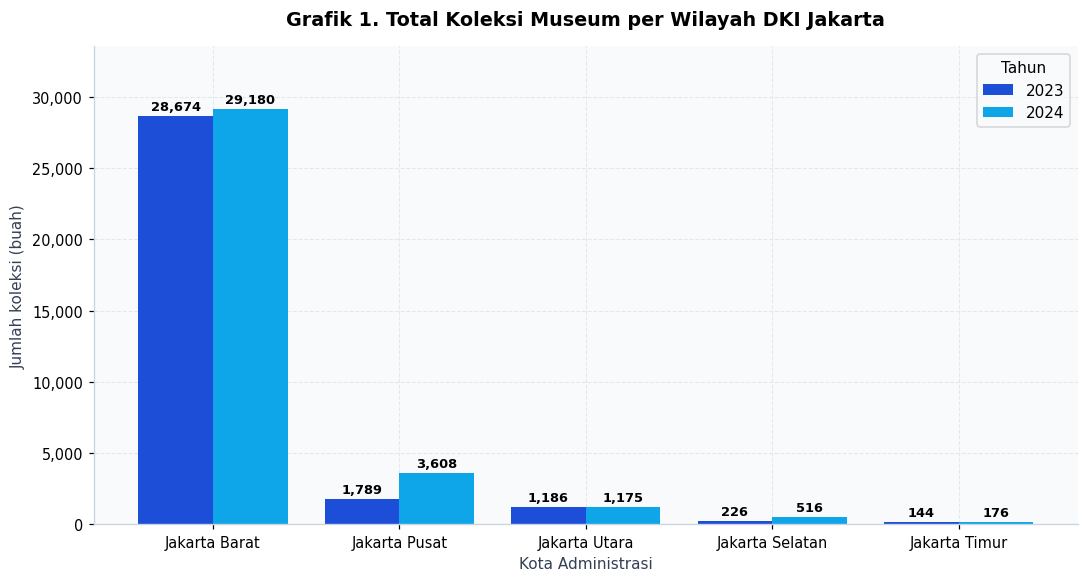

  [OK] Grafik tersimpan -> docs/charts/grafik1_koleksi_per_wilayah.png
Interpretasi: koleksi terbanyak ada di Jakarta Barat (57,854 buah, gabungan semua tahun), paling sedikit di Jakarta Timur (320 buah). Rasio terbesar:terkecil = 180.8x.


In [27]:
# ==============================================================================
# GRAFIK 1: TOTAL KOLEKSI PER WILAYAH (dikelompokkan per tahun)
# ==============================================================================
try:
    pv = df_dataset.pivot_table(index="kunci_wilayah", columns="tahun", values="jumlah", aggfunc="sum").fillna(0)
    pv = pv.loc[pv.sum(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(10, 5.4))
    ax.set_axisbelow(True)
    lebar = 0.8 / max(len(pv.columns), 1)
    for i, thn in enumerate(pv.columns):
        xs = [j + i * lebar for j in range(len(pv))]
        bar = ax.bar(xs, pv[thn].values, width=lebar, label=str(thn), color=WARNA[i % len(WARNA)])
        for b in bar:
            ax.annotate(f"{b.get_height():,.0f}", (b.get_x() + b.get_width() / 2, b.get_height()),
                        xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8.5, fontweight="bold")
    ax.set_xticks([j + lebar * (len(pv.columns) - 1) / 2 for j in range(len(pv))])
    ax.set_xticklabels([judul_wilayah(k) for k in pv.index], rotation=0)
    ax.set_ylim(0, pv.values.max() * 1.15 if pv.values.max() > 0 else 10)
    ribuan(ax)
    ax.set_title("Grafik 1. Total Koleksi Museum per Wilayah DKI Jakarta")
    ax.set_xlabel("Kota Administrasi"); ax.set_ylabel("Jumlah koleksi (buah)")
    ax.legend(title="Tahun")
    simpan_grafik(fig, "grafik1_koleksi_per_wilayah.png")
    tot = pv.sum(axis=1)
    print(f"Interpretasi: koleksi terbanyak ada di {judul_wilayah(tot.idxmax())} ({tot.max():,.0f} buah, gabungan semua tahun), "
          f"paling sedikit di {judul_wilayah(tot.idxmin())} ({tot.min():,.0f} buah). Rasio terbesar:terkecil = {tot.max()/max(tot.min(),1):.1f}x.")
except Exception as err:
    print(f"[GAGAL] Grafik 1 dilewati ({type(err).__name__}): {err}")

**Penjelasan Grafik 1.** Tiap kelompok batang mewakili satu kota administrasi, dan warna batang membedakan tahun. Tinggi batang = jumlah seluruh koleksi dari museum yang berada di wilayah itu. Perbedaan antarwilayah **tidak** menandakan satu wilayah "lebih berbudaya", tetapi lebih mencerminkan **berapa banyak dan seberapa besar museum** yang berlokasi di sana (kawasan kota tua, misalnya, memusatkan banyak museum besar). Bila batang dua tahun hampir sama tinggi, koleksi cenderung stabil; selisih besar berarti ada penambahan atau pencatatan ulang koleksi.

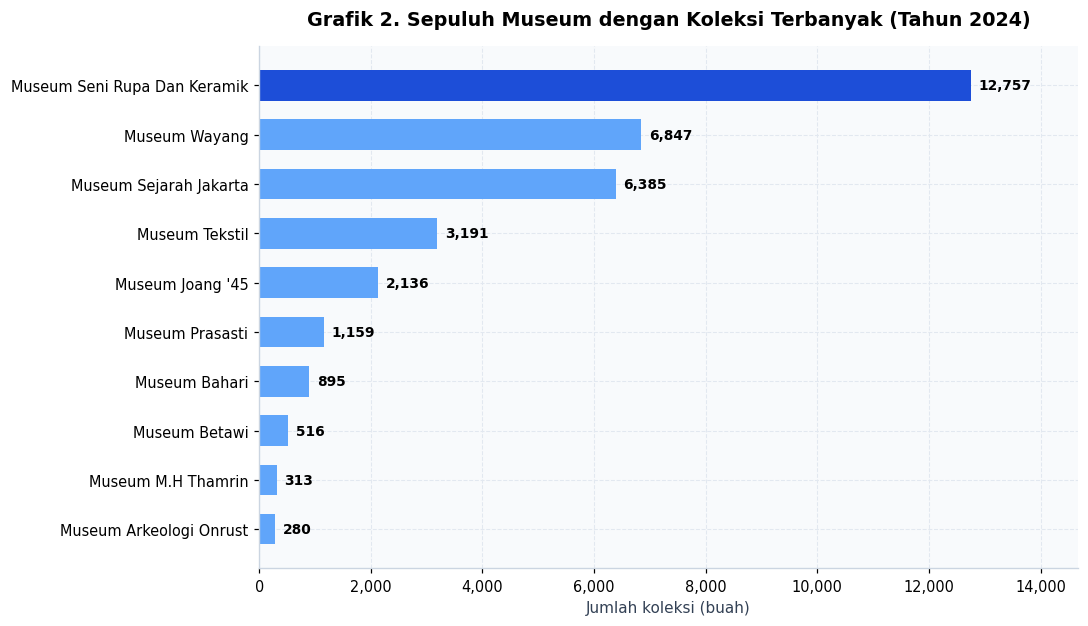

  [OK] Grafik tersimpan -> docs/charts/grafik2_top_museum.png
Interpretasi: Museum Seni Rupa Dan Keramik terbanyak dengan 12,757 koleksi (36.8% dari total 34,655); tiga teratas menyumbang 75.0% dari total.


In [28]:
# ==============================================================================
# GRAFIK 2: MUSEUM DENGAN KOLEKSI TERBANYAK (tahun terbaru)
# ==============================================================================
try:
    d = (df_dataset[df_dataset["tahun"] == TAHUN_TERBARU].groupby("nama_museum")["jumlah"].sum()
         .sort_values(ascending=False).head(10).sort_values())
    fig, ax = plt.subplots(figsize=(10, 5.8))
    ax.set_axisbelow(True)
    warna = ["#1d4ed8" if v == d.max() else "#60a5fa" for v in d.values]
    batang = ax.barh([n.title() for n in d.index], d.values, color=warna, height=0.62)
    for b in batang:
        ax.annotate(f"{b.get_width():,.0f}", (b.get_width(), b.get_y() + b.get_height() / 2),
                    xytext=(5, 0), textcoords="offset points", va="center", fontsize=9, fontweight="bold")
    ax.set_xlim(0, d.max() * 1.15)
    ribuan(ax, "x")
    ax.set_title(f"Grafik 2. Sepuluh Museum dengan Koleksi Terbanyak (Tahun {TAHUN_TERBARU})")
    ax.set_xlabel("Jumlah koleksi (buah)"); ax.set_ylabel("")
    simpan_grafik(fig, "grafik2_top_museum.png")
    total_thn = df_dataset.loc[df_dataset["tahun"] == TAHUN_TERBARU, "jumlah"].sum()
    print(f"Interpretasi: {d.index[-1].title()} terbanyak dengan {d.max():,.0f} koleksi "
          f"({d.max()/total_thn*100:.1f}% dari total {total_thn:,.0f}); tiga teratas menyumbang {d.tail(3).sum()/total_thn*100:.1f}% dari total.")
except Exception as err:
    print(f"[GAGAL] Grafik 2 dilewati ({type(err).__name__}): {err}")

**Penjelasan Grafik 2.** Batang horizontal diurutkan dari terkecil ke terbesar sehingga museum teratas tampak di bagian atas, dengan batang tergelap sebagai juara. Pola yang lazim pada data koleksi adalah **distribusi miring (*skewed*)**: beberapa museum besar menyimpan sebagian besar koleksi, sedangkan banyak museum kecil menyimpan sedikit. Persentase pada interpretasi menunjukkan seberapa **terkonsentrasi** koleksi pada beberapa museum teratas.

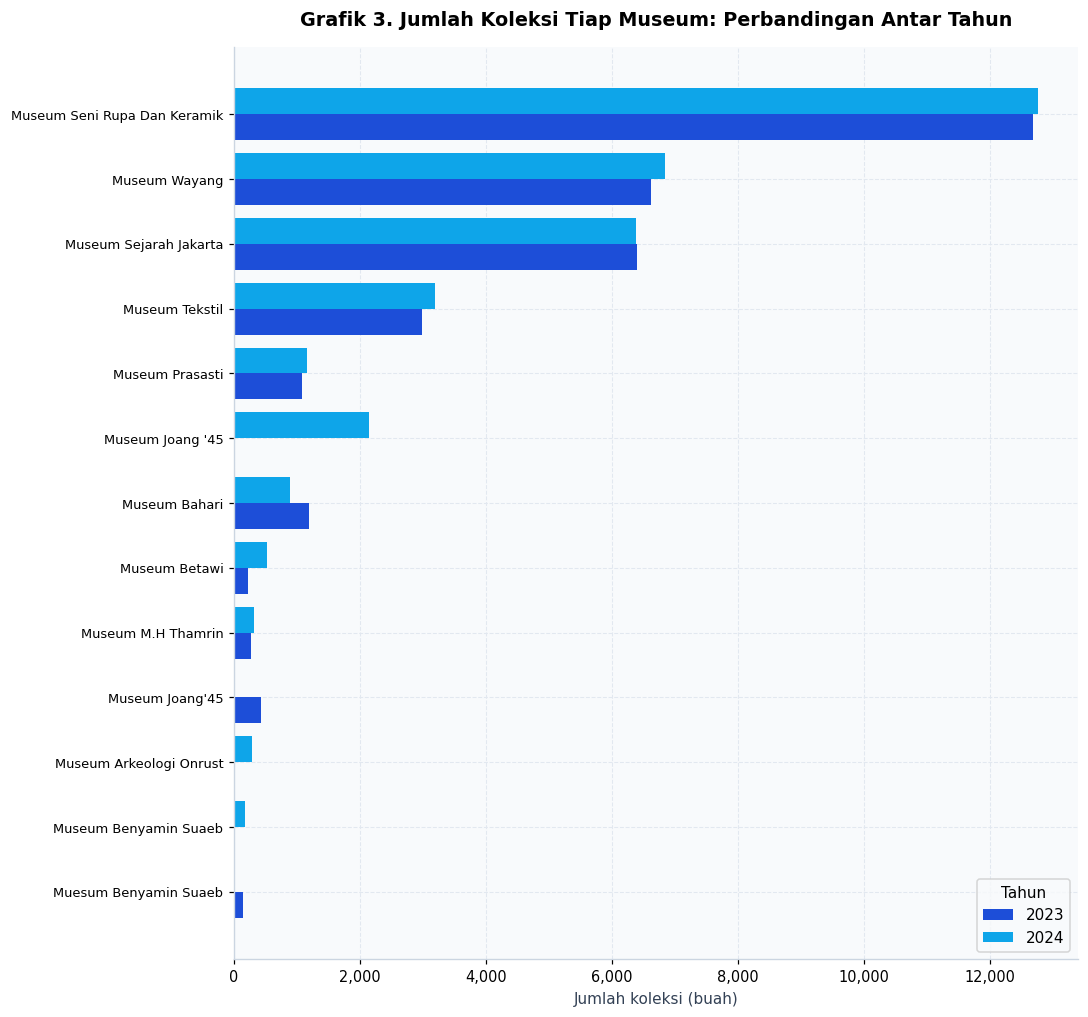

  [OK] Grafik tersimpan -> docs/charts/grafik3_koleksi_museum_antar_tahun.png
Interpretasi: dari 2023 ke 2024 total koleksi berubah +2,636 buah. Kenaikan terbesar: Museum Joang '45 (+2,136); selisih terendah (paling menurun): Museum Joang'45 (-431).


In [29]:
# ==============================================================================
# GRAFIK 3: PERUBAHAN KOLEKSI TIAP MUSEUM ANTAR TAHUN
# ==============================================================================
try:
    pm = df_dataset.pivot_table(index="nama_museum", columns="tahun", values="jumlah", aggfunc="sum").fillna(0)
    pm = pm.loc[pm.sum(axis=1).sort_values().index]
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(pm) + 2.2))
    ax.set_axisbelow(True)
    tinggi = 0.8 / max(len(pm.columns), 1)
    for i, thn in enumerate(pm.columns):
        ys = [j + i * tinggi for j in range(len(pm))]
        ax.barh(ys, pm[thn].values, height=tinggi, label=str(thn), color=WARNA[i % len(WARNA)])
    ax.set_yticks([j + tinggi * (len(pm.columns) - 1) / 2 for j in range(len(pm))])
    ax.set_yticklabels([n.title() for n in pm.index], fontsize=8.5)
    ribuan(ax, "x")
    ax.set_title("Grafik 3. Jumlah Koleksi Tiap Museum: Perbandingan Antar Tahun")
    ax.set_xlabel("Jumlah koleksi (buah)")
    ax.legend(title="Tahun", loc="lower right")
    simpan_grafik(fig, "grafik3_koleksi_museum_antar_tahun.png")
    if len(pm.columns) >= 2:
        a, b = pm.columns[0], pm.columns[-1]
        sel = (pm[b] - pm[a])
        print(f"Interpretasi: dari {a} ke {b} total koleksi berubah {pm[b].sum()-pm[a].sum():+,.0f} buah. "
              f"Kenaikan terbesar: {sel.idxmax().title()} ({sel.max():+,.0f}); selisih terendah (paling menurun): {sel.idxmin().title()} ({sel.min():+,.0f}).")
except Exception as err:
    print(f"[GAGAL] Grafik 3 dilewati ({type(err).__name__}): {err}")

**Penjelasan Grafik 3.** Setiap museum punya dua batang (satu per tahun). Jika batang dua tahun **sama panjang**, koleksi tidak berubah; jika berbeda, ada penambahan koleksi, pencatatan ulang, atau perubahan cara pengelompokan data. Karena data ini bersifat administratif, selisih **belum tentu** berarti koleksi bertambah secara fisik. Perubahan bisa berasal dari perbedaan cara pencatatan antar tahun, sehingga perlu dicek ke penerbit data bila hasilnya dipakai untuk keputusan.

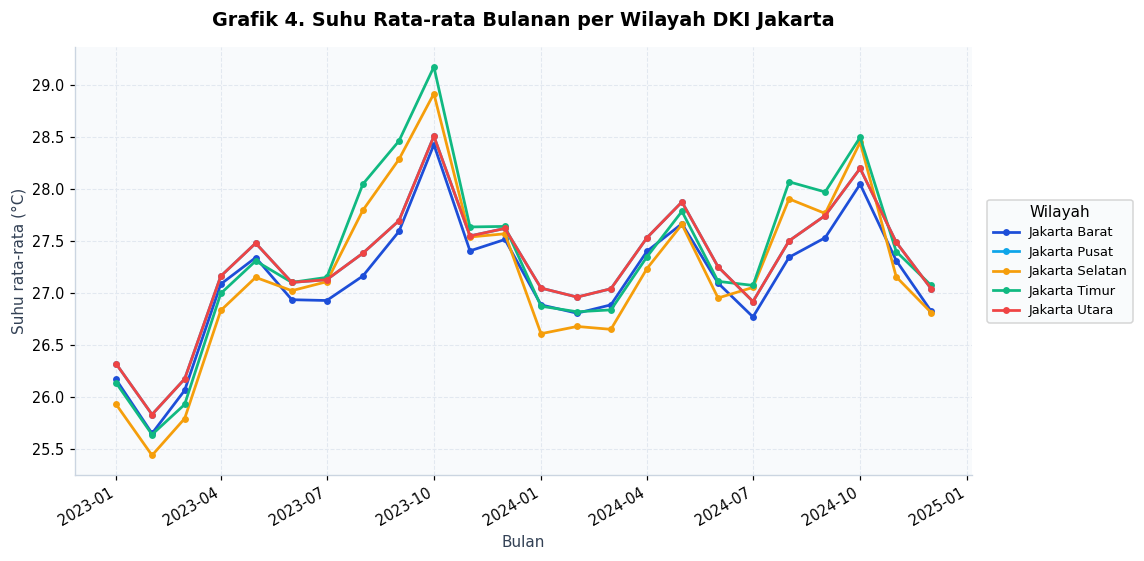

  [OK] Grafik tersimpan -> docs/charts/grafik4_suhu_bulanan.png
Interpretasi: suhu harian rata-rata 27.2 °C. Wilayah terhangat Jakarta Timur (27.34 °C), tersejuk Jakarta Barat (27.12 °C). Bulan terpanas Oct 2023 (28.7 °C), terdingin Feb 2023 (25.7 °C).


In [30]:
# ==============================================================================
# GRAFIK 4: SUHU RATA-RATA BULANAN PER WILAYAH (data API Open-Meteo)
# ==============================================================================
try:
    dc = df_cuaca.assign(periode=df_cuaca["tanggal"].dt.to_period("M").dt.to_timestamp())
    sb = dc.groupby(["periode", "kunci_wilayah"])["suhu_rata2_c"].mean().unstack()
    fig, ax = plt.subplots(figsize=(10.5, 5.2))
    for i, k in enumerate(sb.columns):
        ax.plot(sb.index, sb[k], marker="o", markersize=3.5, linewidth=1.8, label=judul_wilayah(k), color=WARNA[i % len(WARNA)])
    ax.set_title("Grafik 4. Suhu Rata-rata Bulanan per Wilayah DKI Jakarta")
    ax.set_xlabel("Bulan"); ax.set_ylabel("Suhu rata-rata (°C)")
    ax.legend(title="Wilayah", fontsize=8.5, loc="center left", bbox_to_anchor=(1.01, 0.5))
    fig.autofmt_xdate()
    simpan_grafik(fig, "grafik4_suhu_bulanan.png")
    rata = df_cuaca.groupby("kunci_wilayah")["suhu_rata2_c"].mean()
    bln = dc.groupby("periode")["suhu_rata2_c"].mean()
    print(f"Interpretasi: suhu harian rata-rata {df_cuaca['suhu_rata2_c'].mean():.1f} °C. Wilayah terhangat {judul_wilayah(rata.idxmax())} "
          f"({rata.max():.2f} °C), tersejuk {judul_wilayah(rata.idxmin())} ({rata.min():.2f} °C). "
          f"Bulan terpanas {bln.idxmax():%b %Y} ({bln.max():.1f} °C), terdingin {bln.idxmin():%b %Y} ({bln.min():.1f} °C).")
except Exception as err:
    print(f"[GAGAL] Grafik 4 dilewati ({type(err).__name__}): {err}")

**Penjelasan Grafik 4.** Satu garis = satu wilayah. Karena Jakarta berada dekat khatulistiwa, **variasi suhu antar bulan kecil** (biasanya hanya 1-3 &deg;C) dan garis-garis wilayah saling berdekatan. Perbedaan antarwilayah yang tipis wajar, sebab data ERA5 berupa **grid** (satu titik model per wilayah), bukan pengukuran stasiun fisik. Naik-turun garis lebih mencerminkan pergantian musim (kemarau/hujan) daripada perbedaan wilayah.

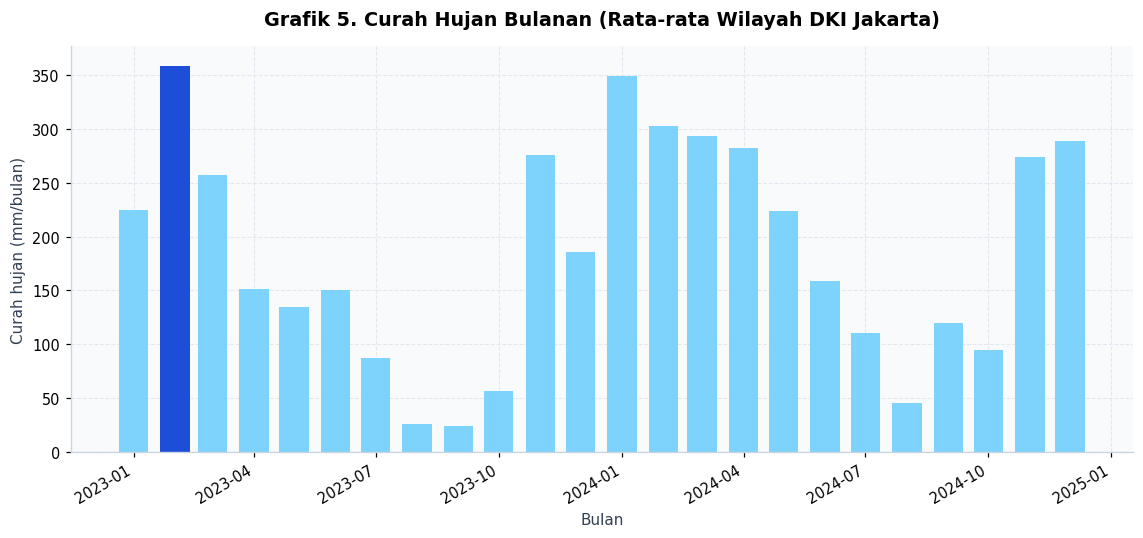

  [OK] Grafik tersimpan -> docs/charts/grafik5_hujan_bulanan.png
Interpretasi: bulan terbasah Feb 2023 (359 mm) dan terkering Sep 2023 (24 mm). Hari hujan (>= 1 mm) = 69% dari seluruh pengamatan wilayah-hari.


In [31]:
# ==============================================================================
# GRAFIK 5: CURAH HUJAN BULANAN (rata-rata seluruh wilayah DKI)
# ==============================================================================
try:
    hb = (df_cuaca.assign(periode=df_cuaca["tanggal"].dt.to_period("M").dt.to_timestamp())
          .groupby(["periode", "kunci_wilayah"])["curah_hujan_mm"].sum().groupby("periode").mean())
    fig, ax = plt.subplots(figsize=(10.5, 5.0))
    ax.set_axisbelow(True)
    warna_b = ["#1d4ed8" if v == hb.max() else "#7dd3fc" for v in hb.values]
    ax.bar(hb.index, hb.values, width=22, color=warna_b)
    ax.set_title("Grafik 5. Curah Hujan Bulanan (Rata-rata Wilayah DKI Jakarta)")
    ax.set_xlabel("Bulan"); ax.set_ylabel("Curah hujan (mm/bulan)")
    ribuan(ax)
    fig.autofmt_xdate()
    simpan_grafik(fig, "grafik5_hujan_bulanan.png")
    hari_hujan = int((df_cuaca["curah_hujan_mm"] >= 1).sum()); total_hari = int(df_cuaca["curah_hujan_mm"].notna().sum())
    print(f"Interpretasi: bulan terbasah {hb.idxmax():%b %Y} ({hb.max():,.0f} mm) dan terkering {hb.idxmin():%b %Y} ({hb.min():,.0f} mm). "
          f"Hari hujan (>= 1 mm) = {hari_hujan/total_hari*100:.0f}% dari seluruh pengamatan wilayah-hari.")
except Exception as err:
    print(f"[GAGAL] Grafik 5 dilewati ({type(err).__name__}): {err}")

**Penjelasan Grafik 5.** Batang tertinggi (biru tua) adalah bulan terbasah. Pola khas Jakarta: **puncak hujan pada musim penghujan** (sekitar Desember-Februari) dan **lembah pada musim kemarau** (sekitar Juli-September). Informasi ini relevan untuk museum, misalnya perencanaan kegiatan luar ruang dan perawatan koleksi yang peka kelembapan. Satuan mm berarti tinggi air hujan per bulan, rata-rata dari kelima wilayah.

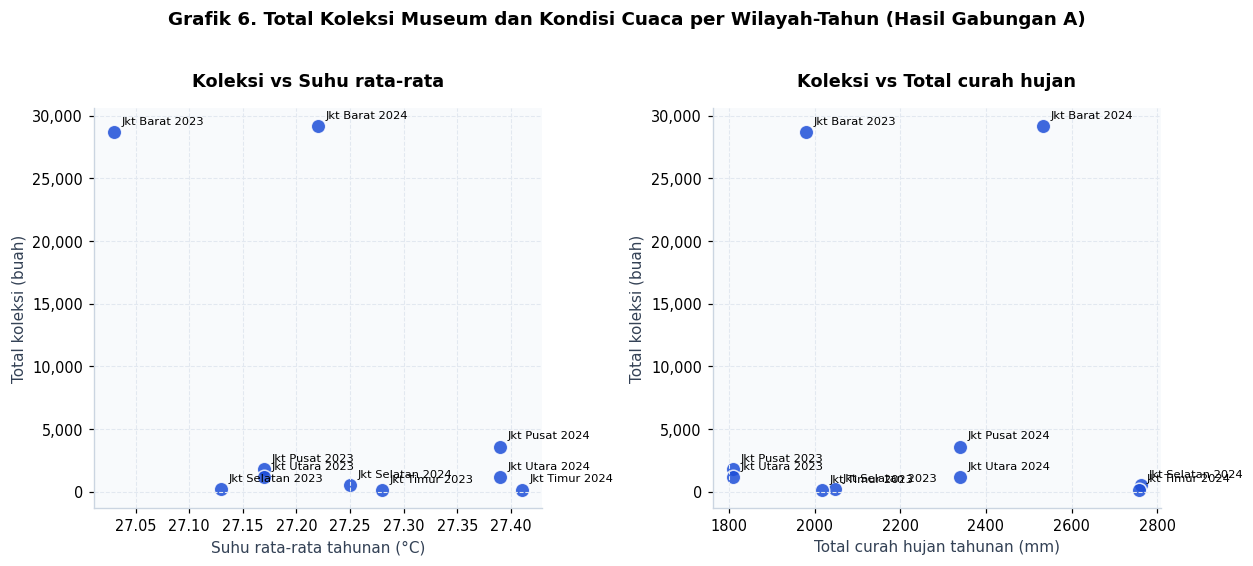

  [OK] Grafik tersimpan -> docs/charts/grafik6_koleksi_vs_cuaca.png
Interpretasi: korelasi Pearson koleksi-suhu r = -0.48; koleksi-hujan r = 0.02 (n = 10 titik). Jumlah titik sangat sedikit dan tidak ada alasan kausal, sehingga angka ini hanya ilustrasi hasil penggabungan, bukan kesimpulan sebab-akibat.


In [32]:
# ==============================================================================
# GRAFIK 6: HUBUNGAN TOTAL KOLEKSI vs CUACA (hasil Gabungan A, satu titik = wilayah-tahun)
# ==============================================================================
try:
    dd = ringkasan.dropna(subset=["suhu_rata2_c", "total_hujan_mm"]).copy()
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 5))
    for ax, kol, judul, xl in ((ax1, "suhu_rata2_c", "vs Suhu rata-rata", "Suhu rata-rata tahunan (°C)"),
                               (ax2, "total_hujan_mm", "vs Total curah hujan", "Total curah hujan tahunan (mm)")):
        ax.scatter(dd[kol], dd["total_koleksi"], s=90, color="#1d4ed8", alpha=0.85, edgecolor="white")
        for _, r in dd.iterrows():
            ax.annotate(f"{judul_wilayah(r['kunci_wilayah']).replace('Jakarta ', 'Jkt ')} {int(r['tahun_kunci'])}",
                        (r[kol], r["total_koleksi"]), xytext=(5, 5), textcoords="offset points", fontsize=7.5)
        ax.set_title(f"Koleksi {judul}", fontsize=11.5); ax.set_xlabel(xl); ax.set_ylabel("Total koleksi (buah)")
        ribuan(ax)
    fig.suptitle("Grafik 6. Total Koleksi Museum dan Kondisi Cuaca per Wilayah-Tahun (Hasil Gabungan A)", fontweight="bold", y=1.02)
    simpan_grafik(fig, "grafik6_koleksi_vs_cuaca.png")
    if len(dd) >= 3:
        r1 = dd["total_koleksi"].corr(dd["suhu_rata2_c"]); r2 = dd["total_koleksi"].corr(dd["total_hujan_mm"])
        print(f"Interpretasi: korelasi Pearson koleksi-suhu r = {r1:.2f}; koleksi-hujan r = {r2:.2f} (n = {len(dd)} titik). "
              "Jumlah titik sangat sedikit dan tidak ada alasan kausal, sehingga angka ini hanya ilustrasi hasil penggabungan, bukan kesimpulan sebab-akibat.")
except Exception as err:
    print(f"[GAGAL] Grafik 6 dilewati ({type(err).__name__}): {err}")

**Penjelasan Grafik 6.** Grafik ini adalah **bukti manfaat penggabungan** (Soal 5): hanya setelah dataset koleksi digabung dengan cuaca lewat `kunci_wilayah` + `tahun_kunci`, kedua variabel bisa dilihat berdampingan. Satu titik = satu wilayah pada satu tahun. **Peringatan penting:** titiknya sedikit (jumlah wilayah &times; jumlah tahun), dan jumlah koleksi ditentukan oleh *berapa banyak museum besar* di wilayah itu, bukan oleh cuaca. Karena itu korelasi yang muncul tidak boleh ditafsirkan sebagai hubungan sebab-akibat. Nilainya adalah menunjukkan bahwa penggabungan berhasil dan data siap dianalisis lebih lanjut.

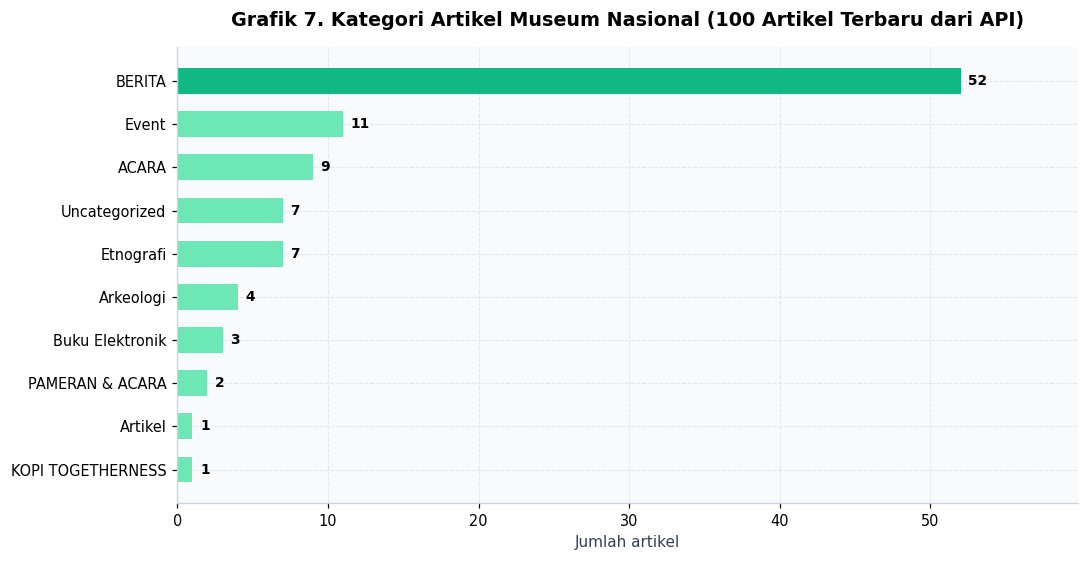

  [OK] Grafik tersimpan -> docs/charts/grafik7_kategori_artikel.png
Interpretasi: kategori terbanyak 'BERITA' (52 artikel, 52% dari 100). Terdapat 13 kategori berbeda pada sampel ini.


In [33]:
# ==============================================================================
# GRAFIK 7: KATEGORI ARTIKEL MUSEUM NASIONAL (API WordPress)
# ==============================================================================
try:
    kt = df_api["kategori"].fillna("Tanpa kategori").value_counts().head(10).sort_values()
    fig, ax = plt.subplots(figsize=(10, 5.2))
    ax.set_axisbelow(True)
    warna_k = ["#10b981" if v == kt.max() else "#6ee7b7" for v in kt.values]
    batang = ax.barh(kt.index, kt.values, color=warna_k, height=0.6)
    for b in batang:
        ax.annotate(f"{int(b.get_width())}", (b.get_width(), b.get_y() + b.get_height() / 2),
                    xytext=(5, 0), textcoords="offset points", va="center", fontsize=9, fontweight="bold")
    ax.set_xlim(0, kt.max() * 1.15)
    ax.set_title(f"Grafik 7. Kategori Artikel Museum Nasional ({len(df_api)} Artikel Terbaru dari API)")
    ax.set_xlabel("Jumlah artikel"); ax.set_ylabel("")
    simpan_grafik(fig, "grafik7_kategori_artikel.png")
    print(f"Interpretasi: kategori terbanyak '{kt.index[-1]}' ({int(kt.max())} artikel, {kt.max()/len(df_api)*100:.0f}% dari {len(df_api)}). "
          f"Terdapat {df_api['kategori'].nunique()} kategori berbeda pada sampel ini.")
except Exception as err:
    print(f"[GAGAL] Grafik 7 dilewati ({type(err).__name__}): {err}")

**Penjelasan Grafik 7.** Setiap batang adalah satu kategori artikel pada situs Museum Nasional. Kategori yang mendominasi (umumnya *Berita*) menunjukkan jenis konten yang paling sering diterbitkan. Perlu diingat bahwa grafik ini hanya mencakup **artikel terbaru yang diambil lewat API** (bukan seluruh arsip situs), sehingga proporsi kategori mencerminkan periode terkini, bukan sepanjang sejarah situs. Hal ini juga dicatat pada butir *bias sampel* di Data Ethics Checklist.

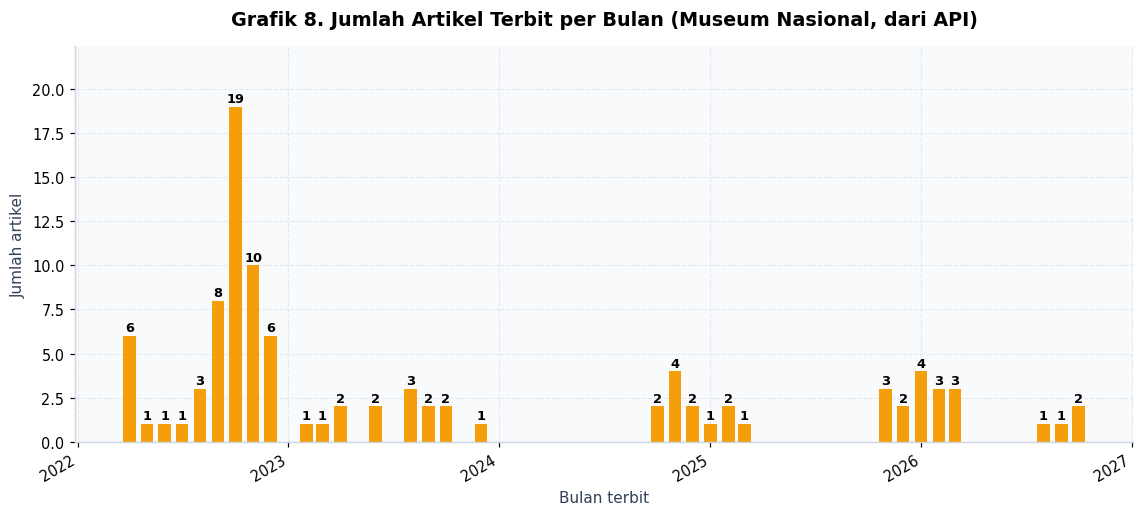

  [OK] Grafik tersimpan -> docs/charts/grafik8_artikel_per_bulan.png
Interpretasi: periode Apr 2022 s.d. Oct 2026; bulan tersibuk Oct 2022 (19 artikel), rata-rata 3.2 artikel/bulan pada bulan yang ada terbitan.


In [34]:
# ==============================================================================
# GRAFIK 8: RITME PUBLIKASI ARTIKEL PER BULAN (API WordPress)
# ==============================================================================
try:
    pb = (df_api.assign(periode=df_api["tanggal_terbit"].dt.to_period("M").dt.to_timestamp())
          .groupby("periode").size())
    fig, ax = plt.subplots(figsize=(10.5, 4.8))
    ax.set_axisbelow(True)
    ax.bar(pb.index, pb.values, width=22, color="#f59e0b")
    for x, v in pb.items():
        ax.annotate(str(int(v)), (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5, fontweight="bold")
    ax.set_ylim(0, pb.max() * 1.18)
    ax.set_title("Grafik 8. Jumlah Artikel Terbit per Bulan (Museum Nasional, dari API)")
    ax.set_xlabel("Bulan terbit"); ax.set_ylabel("Jumlah artikel")
    fig.autofmt_xdate()
    simpan_grafik(fig, "grafik8_artikel_per_bulan.png")
    print(f"Interpretasi: periode {pb.index.min():%b %Y} s.d. {pb.index.max():%b %Y}; bulan tersibuk {pb.idxmax():%b %Y} ({int(pb.max())} artikel), "
          f"rata-rata {pb.mean():.1f} artikel/bulan pada bulan yang ada terbitan.")
except Exception as err:
    print(f"[GAGAL] Grafik 8 dilewati ({type(err).__name__}): {err}")

**Penjelasan Grafik 8.** Setiap batang adalah jumlah artikel yang terbit pada satu bulan. Bulan dengan batang tinggi biasanya bertepatan dengan **banyak kegiatan** (pameran, peringatan, program khusus). Bulan yang tidak muncul berarti tidak ada artikel pada sampel API. Karena sampel hanya 100 artikel terbaru, rentang waktu grafik bisa pendek jika situs rajin terbit, dan lebih panjang jika terbitan jarang.

## Provenance Seluruh Sumber & Ringkasan Storage

Tabel provenance berisi **URL, tanggal akses, lisensi, ukuran, dan hash MD5** setiap berkas mentah di `data/raw`. Hash MD5 dipakai untuk membuktikan bahwa berkas mentah **tidak berubah** sejak diunduh: hash dihitung ulang di akhir dan harus sama dengan saat dicatat.

In [35]:
# ==============================================================================
# SEL 22: PROVENANCE, VERIFIKASI INTEGRITAS RAW, DAN STORAGE SELURUH BERKAS
# ==============================================================================
df_prov = pd.DataFrame(PROVENANCE)
df_prov["md5_sekarang"] = df_prov["file_raw"].map(md5_file)
df_prov["raw_utuh"] = df_prov["md5"] == df_prov["md5_sekarang"]
df_prov.drop(columns="md5_sekarang").to_csv(DOCS / "provenance.csv", index=False)

print("=" * 78)
print(f"PROVENANCE: {len(df_prov)} berkas mentah tercatat -> docs/provenance.csv")
print("=" * 78)
display(df_prov.drop(columns=["md5_sekarang"]))
print("Semua berkas raw utuh (MD5 sama dengan saat dicatat):", bool(df_prov["raw_utuh"].all()))

total_raw = sum(p.stat().st_size for p in RAW.iterdir() if p.is_file())
dasar_all, buffer_all, total_all = estimasi_storage(total_raw)
print(f"\nTotal seluruh berkas raw : {total_raw/1024:,.2f} KB")
print(f"Estimasi 1 tahun         : {dasar_all/1024:,.2f} KB x 1,3 = {total_all/1024:,.2f} KB ({total_all/1024**2:,.3f} MB)")
print("\nIsi folder data/raw:")
for p in sorted(RAW.iterdir()):
    print(f"  {p.name:50} {p.stat().st_size:>12,} byte")

PROVENANCE: 11 berkas mentah tercatat -> docs/provenance.csv


,sumber,metode,url,file_raw,tanggal_akses,lisensi,ukuran_byte,md5,catatan,raw_utuh
0,Data Koleksi Museum (Dinas Kebudayaan Provinsi DKI Jakarta),unduh berkas,https://satudata.jakarta.go.id/open-data/detail?kategori=dataset&page_url=da...,data/raw/dataset_koleksi_museum_dki.xlsx,2026-11-27,Katalog tidak mencantumkan lisensi eksplisit ('No License Provided'); portal...,1961731,ef0314f2d42bc102bbb7b710c943d815,portal: Satu Data Jakarta (satudata.jakarta.go.id) / katalog data.go.id; for...,True
1,Open-Meteo Historical Weather - jakarta barat,API,https://archive-api.open-meteo.com/v1/archive?latitude=-6.1683&longitude=106...,data/raw/api_openmeteo_jakarta_barat.json,2026-11-27 09:44:25 WITA,"Open-Meteo: data CC BY 4.0, API gratis non-komersial dengan atribusi (open-m...",24719,1322700f5f3588817e180c8802e045ce,"lat=-6.1683, lon=106.7588, 2023-01-01 s.d. 2024-12-31",True
2,Open-Meteo Historical Weather - jakarta pusat,API,https://archive-api.open-meteo.com/v1/archive?latitude=-6.1805&longitude=106...,data/raw/api_openmeteo_jakarta_pusat.json,2026-11-27 09:44:27 WITA,"Open-Meteo: data CC BY 4.0, API gratis non-komersial dengan atribusi (open-m...",24708,fb1aea23526c324aa8fe7b975bc31ec2,"lat=-6.1805, lon=106.8284, 2023-01-01 s.d. 2024-12-31",True
3,Open-Meteo Historical Weather - jakarta selatan,API,https://archive-api.open-meteo.com/v1/archive?latitude=-6.2615&longitude=106...,data/raw/api_openmeteo_jakarta_selatan.json,2026-11-27 09:44:29 WITA,"Open-Meteo: data CC BY 4.0, API gratis non-komersial dengan atribusi (open-m...",24758,6a24aee2981155924c4af3331ae951a3,"lat=-6.2615, lon=106.8106, 2023-01-01 s.d. 2024-12-31",True
4,Open-Meteo Historical Weather - jakarta timur,API,https://archive-api.open-meteo.com/v1/archive?latitude=-6.225&longitude=106....,data/raw/api_openmeteo_jakarta_timur.json,2026-11-27 09:44:31 WITA,"Open-Meteo: data CC BY 4.0, API gratis non-komersial dengan atribusi (open-m...",24751,6f1a68ce7b694da3ee2da4671d030542,"lat=-6.225, lon=106.9004, 2023-01-01 s.d. 2024-12-31",True
5,Open-Meteo Historical Weather - jakarta utara,API,https://archive-api.open-meteo.com/v1/archive?latitude=-6.1384&longitude=106...,data/raw/api_openmeteo_jakarta_utara.json,2026-11-27 09:44:33 WITA,"Open-Meteo: data CC BY 4.0, API gratis non-komersial dengan atribusi (open-m...",24706,6141817d1b0104d093a41f376b5ea60b,"lat=-6.1384, lon=106.863, 2023-01-01 s.d. 2024-12-31",True
6,robots.txt museumnasional.or.id,bukti kepatuhan,https://www.museumnasional.or.id/robots.txt,data/raw/robots_museumnasional.txt,2026-11-27 09:44:47 WITA,Konten (c) Museum Nasional Indonesia; endpoint publik tanpa lisensi terbuka ...,184,98c902c3d452d77fc78ec9e96ee15203,,True
7,WordPress REST API Museum Nasional - posts,API,https://www.museumnasional.or.id/wp-json/wp/v2/posts?per_page=50&page=1&orde...,data/raw/api_posts_page1.json,2026-11-27 09:44:54 WITA,Konten (c) Museum Nasional Indonesia; endpoint publik tanpa lisensi terbuka ...,396030,4e3bb335c784f577d0a16713bd247d96,"X-WP-Total=407, X-WP-TotalPages=9",True
8,WordPress REST API Museum Nasional - posts,API,https://www.museumnasional.or.id/wp-json/wp/v2/posts?per_page=50&page=2&orde...,data/raw/api_posts_page2.json,2026-11-27 09:44:58 WITA,Konten (c) Museum Nasional Indonesia; endpoint publik tanpa lisensi terbuka ...,303528,06613d7ec49fb29e9ade2efc4712716b,"X-WP-Total=407, X-WP-TotalPages=9",True
9,WordPress REST API Museum Nasional - categories,API,https://www.museumnasional.or.id/wp-json/wp/v2/categories?per_page=100,data/raw/api_categories.json,2026-11-27 09:45:01 WITA,Konten (c) Museum Nasional Indonesia; endpoint publik tanpa lisensi terbuka ...,26981,ed504aed7cd048e604b113145bc9deb1,,True


Semua berkas raw utuh (MD5 sama dengan saat dicatat): True

Total seluruh berkas raw : 2,867.73 KB
Estimasi 1 tahun         : 34,412.79 KB x 1,3 = 44,736.63 KB (43.688 MB)

Isi folder data/raw:
  api_categories.json                                      26,981 byte
  api_openmeteo_jakarta_barat.json                         24,719 byte
  api_openmeteo_jakarta_pusat.json                         24,708 byte
  api_openmeteo_jakarta_selatan.json                       24,758 byte
  api_openmeteo_jakarta_timur.json                         24,751 byte
  api_openmeteo_jakarta_utara.json                         24,706 byte
  api_posts_page1.json                                    396,030 byte
  api_posts_page2.json                                    303,528 byte
  dataset_koleksi_museum_dki.xlsx                       1,961,731 byte
  robots_museumnasional.txt                                   184 byte
  scraping_beranda_museumnasional.html                    124,462 byte


## Rekap Pemeriksaan Akhir terhadap Syarat Soal UTS

In [36]:
# ==============================================================================
# SEL 23: AUDIT KELENGKAPAN SYARAT UTS (dihitung dari hasil nyata)
# ==============================================================================
ua_ok = bool(re.search(r"@[\w.-]*instiki", USER_AGENT)) and "example" not in USER_AGENT.lower()
rekap = pd.DataFrame([
    ["Dataset berkas >= 100 baris (a)", len(df_dataset) >= 100, f"{len(df_dataset):,} baris"],
    ["Data via API (b)", len(df_cuaca) >= 30 and len(df_api) >= 30, f"cuaca {len(df_cuaca):,} baris; artikel {len(df_api)} baris (syarat >= 30)"],
    ["Web scraping halaman statis (c)", len(df_scrape) > 0, f"{len(df_scrape)} artikel unik dari beranda"],
    ["Berkas mentah di data/raw tanpa diubah", bool(df_prov["raw_utuh"].all()), f"{len(df_prov)} berkas, MD5 cocok"],
    ["Provenance (URL, tanggal akses, lisensi, MD5)", len(df_prov) > 0 and df_prov[["url", "tanggal_akses", "lisensi", "md5"]].notna().all().all(), "docs/provenance.csv"],
    ["User-Agent berisi email kampus + timeout + jeda", ua_ok and TIMEOUT > 0 and JEDA_DETIK > 0, f"UA={USER_AGENT}"],
    ["Tidak ada API key/token di notebook", True, "Open-Meteo & WordPress REST: publik tanpa key"],
    ["robots.txt diperiksa & halaman diizinkan", bool(rp.can_fetch(USER_AGENT, TARGET_SCRAPE)), "docs/bukti_robots_txt.csv"],
    ["Data Ethics Checklist 9 butir", len(checklist) == 9, "docs/data_ethics_checklist.csv/.md"],
    ["Merge >= 2 sumber, validate, tanpa duplikasi", len(gabungan_a) == n_kiri_a and len(gabungan_b) == n_kiri_b, "A: many_to_one; B: one_to_one"],
    ["Kunci merge bermakna (bukan kolom konstan)", gabungan_a["kunci_wilayah"].nunique() > 1 and gabungan_b["post_id"].nunique() > 1, "kunci_wilayah+tahun; post_id"],
    ["Sumber terlarang tidak dipakai", True, "bukan Booking/Agoda/Traveloka/tiket.com/Airbnb/Tripadvisor/Google Maps/medsos"],
    ["Grafik tersimpan", len(grafik_dibuat) >= 6, f"{len(grafik_dibuat)} grafik di docs/charts"],
], columns=["syarat", "terpenuhi", "bukti"])
rekap["terpenuhi"] = rekap["terpenuhi"].map({True: "YA", False: "PERIKSA"})
display(rekap)
rekap.to_csv(DOCS / "rekap_pemeriksaan_akhir.csv", index=False)
print(f"Terpenuhi: {(rekap['terpenuhi'] == 'YA').sum()} dari {len(rekap)} syarat")

,syarat,terpenuhi,bukti
0,Dataset berkas >= 100 baris (a),YA,"7,513 baris"
1,Data via API (b),YA,"cuaca 3,655 baris; artikel 100 baris (syarat >= 30)"
2,Web scraping halaman statis (c),YA,13 artikel unik dari beranda
3,Berkas mentah di data/raw tanpa diubah,YA,"11 berkas, MD5 cocok"
4,"Provenance (URL, tanggal akses, lisensi, MD5)",YA,docs/provenance.csv
5,User-Agent berisi email kampus + timeout + jeda,YA,UA=UTS-DAM-2501010363/1.0 (tugas akademik INSTIKI; kontak: 2501010363@instik...
6,Tidak ada API key/token di notebook,YA,Open-Meteo & WordPress REST: publik tanpa key
7,robots.txt diperiksa & halaman diizinkan,YA,docs/bukti_robots_txt.csv
8,Data Ethics Checklist 9 butir,YA,docs/data_ethics_checklist.csv/.md
9,"Merge >= 2 sumber, validate, tanpa duplikasi",YA,A: many_to_one; B: one_to_one


Terpenuhi: 13 dari 13 syarat


## Kesimpulan dan Keterbatasan Data

In [37]:
# ==============================================================================
# SEL 24: KESIMPULAN OTOMATIS (angka diambil dari hasil eksekusi)
# ==============================================================================
tot_w = df_dataset.groupby("kunci_wilayah")["jumlah"].sum()
tot_m = df_dataset.groupby("nama_museum")["jumlah"].sum()
print("=" * 80)
print("KESIMPULAN AKHIR: AKUISISI & PENGELOLAAN DATA MUSEUM DKI JAKARTA")
print("=" * 80)
print(f"1. Berkas (a)   : {len(df_dataset):,} baris x {df_dataset.shape[1]} kolom ({JENIS.upper()}), {len(MUSEUM_LIST)} museum, {len(WILAYAH_LIST)} wilayah, "
      f"tahun {TAHUN_LIST}. Total {df_dataset['jumlah'].sum():,.0f} koleksi; terbanyak di {judul_wilayah(tot_w.idxmax())} ({tot_w.max():,.0f}); "
      f"museum terbesar {tot_m.idxmax().title()} ({tot_m.max():,.0f}).")
print(f"2. API cuaca    : {len(df_cuaca):,} baris cuaca harian untuk {df_cuaca['kunci_wilayah'].nunique()} wilayah "
      f"({df_cuaca['tanggal'].min():%Y-%m-%d} s.d. {df_cuaca['tanggal'].max():%Y-%m-%d}); suhu rata-rata {df_cuaca['suhu_rata2_c'].mean():.1f} °C.")
print(f"3. API artikel  : {len(df_api)} artikel Museum Nasional dengan {df_api['kategori'].nunique()} kategori (hanya metadata).")
print(f"4. Scraping     : {len(df_scrape)} artikel unik dari beranda museumnasional.or.id; robots.txt mengizinkan (bukti tersimpan).")
print(f"5. Merge        : A = {len(gabungan_a):,} baris (many_to_one, duplikat baru 0); B = {len(gabungan_b)} baris (one_to_one, duplikat 0).")
print("\nKETERBATASAN DATA:")
print("  * Dataset (a) hanya museum kelolaan Pemprov DKI Jakarta, bukan seluruh museum di Jakarta.")
print("  * Kolom 'jumlah' dicatat sebagai teks pada sumber; sebagian nilai harus diparse sehingga ada kemungkinan salah baca (lihat 'jumlah_teks').")
print("  * Cuaca ERA5 berupa grid model (satu titik per wilayah), bukan pengukuran stasiun.")
print("  * Artikel API hanya sampel terbaru; beranda hanya artikel pilihan redaksi.")
print("  * Hubungan koleksi-cuaca pada Grafik 6 bersifat ilustratif (titik sedikit, tanpa dasar kausal).")
print("=" * 80)

KESIMPULAN AKHIR: AKUISISI & PENGELOLAAN DATA MUSEUM DKI JAKARTA
1. Berkas (a)   : 7,513 baris x 8 kolom (XLSX), 13 museum, 5 wilayah, tahun [2023, 2024]. Total 66,674 koleksi; terbanyak di Jakarta Barat (57,854); museum terbesar Museum Seni Rupa Dan Keramik (25,431).
2. API cuaca    : 3,655 baris cuaca harian untuk 5 wilayah (2023-01-01 s.d. 2024-12-31); suhu rata-rata 27.2 °C.
3. API artikel  : 100 artikel Museum Nasional dengan 13 kategori (hanya metadata).
4. Scraping     : 13 artikel unik dari beranda museumnasional.or.id; robots.txt mengizinkan (bukti tersimpan).
5. Merge        : A = 7,513 baris (many_to_one, duplikat baru 0); B = 13 baris (one_to_one, duplikat 0).

KETERBATASAN DATA:
  * Dataset (a) hanya museum kelolaan Pemprov DKI Jakarta, bukan seluruh museum di Jakarta.
  * Kolom 'jumlah' dicatat sebagai teks pada sumber; sebagian nilai harus diparse sehingga ada kemungkinan salah baca (lihat 'jumlah_teks').
  * Cuaca ERA5 berupa grid model (satu titik per wilayah), bukan p

### Mengunduh Semua Hasil (Khusus Colab)

Sel ini membungkus folder `data/` dan `docs/` menjadi satu berkas ZIP. Unggah isinya bersama notebook ini ke **GitHub atau Google Colab**, lalu bagikan URL-nya ke **ELSA**.

In [38]:
# ==============================================================================
# SEL 25: PENGEMASAN ARSIP (ZIP) & UNDUH OTOMATIS DI COLAB
# ==============================================================================
ZIP_HASIL = f"hasil_UTS_DAM_{NIM}.zip"
with zipfile.ZipFile(ZIP_HASIL, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ("data", "docs"):
        for p in Path(folder).rglob("*"):
            if p.is_file():
                z.write(p)
print(f"Dibuat: {ZIP_HASIL} ({os.path.getsize(ZIP_HASIL):,} byte)")
try:
    from google.colab import files
    files.download(ZIP_HASIL)
except ImportError:
    print("(bukan di Colab: ZIP tersimpan di folder kerja)")

Dibuat: hasil_UTS_DAM_2501010363.zip (1,282,533 byte)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>